# Fraud / Anomaly Detection on Imbalanced Data

## Isolation Forest vs One-Class SVM vs PyTorch Autoencoder

### Regional Furniture Workshop
### Week 4 — Specialist Advanced Build

**Role:** Member 5 — Individual Contributor  
**Primary Tools:** scikit-learn + PyTorch

## 1. Scope Statement

The system is designed for a regional furniture workshop to identify rare and unusual transaction behaviour that may indicate fraud, abuse, or other suspicious events.

The system is intended as a decision-support tool that prioritizes transactions for human review rather than making fully autonomous fraud decisions.

The project focuses on heavily imbalanced transaction data, where suspicious events represent less than 2% of all records.

## 2. Success Criteria

- At least 2,600 transaction records
- Less than 2% suspicious transactions
- Five behavioural features
- Time-based train/validation/test split
- Isolation Forest
- One-Class SVM
- PyTorch Autoencoder
- PR-AUC
- Precision@50
- Cost-based threshold selection
- Weekly review workload estimation
- 20 unusual-input robustness tests

### Measurable Target

Target Precision@50: at least 25%

Target weekly manual-review workload: below 10 hours

## 3. Dataset Design

This project uses a synthetic transaction dataset representing a Regional Furniture Workshop.

The dataset will contain 5,000 transaction records, with approximately 1.5% suspicious transactions. The data will represent realistic purchasing and operational behaviour while maintaining a severe class imbalance suitable for rare-event anomaly detection.

A timestamp-based structure will be used so that the dataset can later be divided into training, validation, and test periods without randomly mixing past and future observations.

### Dataset Design Goals

- Total records: 5,000
- Target suspicious rate: approximately 1.5%
- Normal transactions: approximately 98.5%
- Time-based transaction data
- Furniture-workshop business context
- No future-information leakage
- Behavioural features generated only from information available at or before the transaction time

## 3. Dataset Design

### Business Context

The dataset represents transactions made through a Regional Furniture Workshop. The purpose is to identify rare suspicious transactions that may require further human investigation.

### Dataset Size and Class Imbalance

* Total records: **5,000**
* Suspicious records: **75**
* Normal records: **4,925**
* Suspicious rate: **1.5%**
* This class distribution is intentionally highly imbalanced to represent a rare-event detection problem.

### Planned Raw Features

| Feature                | Description                                                          |
| ---------------------- | -------------------------------------------------------------------- |
| `transaction_id`       | Unique identifier for each transaction                               |
| `timestamp`            | Date and time of the transaction                                     |
| `customer_id`          | Identifier of the customer                                           |
| `employee_id`          | Identifier of the employee handling the transaction                  |
| `product_category`     | Furniture category purchased                                         |
| `quantity`             | Number of items in the transaction                                   |
| `unit_price`           | Price of one item                                                    |
| `amount`               | Total transaction amount                                             |
| `discount_pct`         | Discount applied to the transaction                                  |
| `payment_method`       | Payment method used                                                  |
| `delivery_distance_km` | Delivery distance                                                    |
| `is_return`            | Whether the transaction is associated with a return                  |
| `customer_tenure_days` | Number of days since the customer first interacted with the workshop |
| `transaction_note`     | Short text note associated with the transaction                      |
| `is_suspicious`        | Ground-truth label used only for evaluation                          |

### Behavioural Features to Engineer

Five behavioural features will be created using information available at or before each transaction:

1. `transaction_velocity_24h` — number of previous transactions by the same customer within the previous 24 hours.
2. `amount_deviation_from_history` — difference between the current amount and the customer's previous typical transaction amount.
3. `time_of_day_deviation` — difference between the current transaction hour and the customer's previous typical transaction time.
4. `discount_deviation_from_history` — difference between the current discount and the customer's previous typical discount.
5. `return_frequency_30d` — number of previous returns by the same customer within the previous 30 days.

### Leakage Prevention

The suspicious label will not be used as an input feature for any detector. Behavioural features will be calculated from historical information only, so future transactions and the current transaction's outcome will not be used to construct the features.

### Time Structure

Transactions will be ordered chronologically and later divided into training, validation, and test periods using a time-based split rather than a random split.


In [1]:
from pathlib import Path
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nCurrent working directory:")
print(Path.cwd())

Python executable:
C:\Users\ahmed\anaconda3\envs\week4_ai\python.exe

Python version:
3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]

Current working directory:
C:\Users\ahmed\Desktop\4th project\notebooks


In [3]:
import numpy as np
import pandas as pd
from pathlib import Path

# Reproducibility
np.random.seed(42)

# --------------------------------------------------
# 1. Basic configuration
# --------------------------------------------------
N_RECORDS = 5000
N_SUSPICIOUS = 75

# Project root is one level above the notebooks folder
PROJECT_ROOT = Path("..")
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Create chronological timestamps
# --------------------------------------------------
start_date = pd.Timestamp("2026-01-01 00:00:00")
end_date = pd.Timestamp("2026-06-30 23:59:59")

random_seconds = np.random.randint(
    0,
    int((end_date - start_date).total_seconds()),
    size=N_RECORDS
)

# Convert to a mutable NumPy array
timestamps = np.array(
    start_date + pd.to_timedelta(random_seconds, unit="s"),
    dtype=object
)

# --------------------------------------------------
# 3. Workshop business categories
# --------------------------------------------------
product_categories = [
    "Sofa",
    "Dining Table",
    "Bed",
    "Wardrobe",
    "Office Desk",
    "Chair",
    "Coffee Table",
    "Bookshelf"
]

payment_methods = [
    "Cash",
    "Card",
    "Bank Transfer",
    "Mobile Wallet"
]

# --------------------------------------------------
# 4. Customer and employee information
# --------------------------------------------------
customer_ids = np.random.choice(
    [f"CUST_{i:04d}" for i in range(1, 701)],
    size=N_RECORDS
)

employee_ids = np.random.choice(
    [f"EMP_{i:03d}" for i in range(1, 31)],
    size=N_RECORDS
)

# --------------------------------------------------
# 5. Transaction characteristics
# --------------------------------------------------
product_category = np.random.choice(
    product_categories,
    size=N_RECORDS,
    p=[0.16, 0.13, 0.15, 0.12, 0.10, 0.14, 0.10, 0.10]
)

quantity = np.random.choice(
    [1, 2, 3, 4, 5],
    size=N_RECORDS,
    p=[0.48, 0.26, 0.14, 0.08, 0.04]
)

# Approximate realistic furniture unit prices
price_ranges = {
    "Sofa": (25000, 140000),
    "Dining Table": (18000, 90000),
    "Bed": (30000, 120000),
    "Wardrobe": (28000, 110000),
    "Office Desk": (12000, 65000),
    "Chair": (4000, 25000),
    "Coffee Table": (7000, 35000),
    "Bookshelf": (9000, 45000)
}

unit_price = np.array([
    np.random.uniform(*price_ranges[category])
    for category in product_category
])

discount_pct = np.clip(
    np.random.normal(loc=8, scale=4, size=N_RECORDS),
    0,
    25
)

amount = quantity * unit_price * (1 - discount_pct / 100)

delivery_distance_km = np.clip(
    np.random.gamma(shape=2.2, scale=8, size=N_RECORDS),
    1,
    80
)

is_return = np.random.choice(
    [0, 1],
    size=N_RECORDS,
    p=[0.94, 0.06]
)

customer_tenure_days = np.random.randint(
    30,
    2500,
    size=N_RECORDS
)

# --------------------------------------------------
# 6. Transaction notes
# --------------------------------------------------
normal_notes = [
    "Standard furniture order",
    "Customer requested delivery",
    "Regular workshop transaction",
    "Custom furniture order",
    "Repeat customer",
    "Payment confirmed",
    "Delivery scheduled",
    "Order processed normally"
]

transaction_note = np.random.choice(
    normal_notes,
    size=N_RECORDS
).astype(object)

# --------------------------------------------------
# 7. Suspicious labels
# --------------------------------------------------
is_suspicious = np.zeros(N_RECORDS, dtype=int)

# Select exactly 75 suspicious transactions
suspicious_indices = np.random.choice(
    N_RECORDS,
    size=N_SUSPICIOUS,
    replace=False
)

is_suspicious[suspicious_indices] = 1

# --------------------------------------------------
# 8. Inject suspicious behavioural patterns
# --------------------------------------------------
for idx in suspicious_indices:

    pattern = np.random.choice(
        [
            "high_amount",
            "extreme_discount",
            "late_transaction",
            "rapid_repeat",
            "return_activity"
        ]
    )

    if pattern == "high_amount":
        quantity[idx] = np.random.randint(6, 16)

        unit_price[idx] *= np.random.uniform(1.5, 3.0)

        amount[idx] = (
            quantity[idx]
            * unit_price[idx]
            * (1 - discount_pct[idx] / 100)
        )

        transaction_note[idx] = "Urgent large furniture order"

    elif pattern == "extreme_discount":
        discount_pct[idx] = np.random.uniform(35, 70)

        amount[idx] = (
            quantity[idx]
            * unit_price[idx]
            * (1 - discount_pct[idx] / 100)
        )

        transaction_note[idx] = "Special discount requested urgently"

    elif pattern == "late_transaction":
        base_date = pd.Timestamp(timestamps[idx]).normalize()

        timestamps[idx] = base_date + pd.Timedelta(
            hours=int(np.random.choice([0, 1, 2, 3, 23]))
        )

        transaction_note[idx] = "Late-night transaction request"

    elif pattern == "rapid_repeat":
        quantity[idx] = np.random.randint(4, 10)

        amount[idx] *= np.random.uniform(1.8, 3.5)

        transaction_note[idx] = "Multiple urgent orders"

    elif pattern == "return_activity":
        is_return[idx] = 1

        transaction_note[idx] = "Frequent return/refund request"

# --------------------------------------------------
# 9. Create DataFrame
# --------------------------------------------------
df = pd.DataFrame({
    "transaction_id": [
        f"TXN_{i:05d}"
        for i in range(1, N_RECORDS + 1)
    ],

    "timestamp": timestamps,

    "customer_id": customer_ids,

    "employee_id": employee_ids,

    "product_category": product_category,

    "quantity": quantity,

    "unit_price": unit_price,

    "amount": amount,

    "discount_pct": discount_pct,

    "payment_method": np.random.choice(
        payment_methods,
        size=N_RECORDS
    ),

    "delivery_distance_km": delivery_distance_km,

    "is_return": is_return,

    "customer_tenure_days": customer_tenure_days,

    "transaction_note": transaction_note,

    "is_suspicious": is_suspicious
})

# --------------------------------------------------
# 10. Sort chronologically
# --------------------------------------------------
df = df.sort_values(
    "timestamp"
).reset_index(drop=True)

# --------------------------------------------------
# 11. Save raw dataset
# --------------------------------------------------
raw_file = (
    RAW_DATA_DIR
    / "furniture_workshop_transactions.csv"
)

df.to_csv(
    raw_file,
    index=False
)

# --------------------------------------------------
# 12. Verification
# --------------------------------------------------
print("Dataset created successfully.")
print(f"Shape: {df.shape}")
print(
    f"Suspicious records: "
    f"{df['is_suspicious'].sum()}"
)
print(
    f"Suspicious rate: "
    f"{df['is_suspicious'].mean() * 100:.2f}%"
)
print(
    f"Saved to: "
    f"{raw_file.resolve()}"
)

print("\nFirst 5 rows:")
display(df.head())

print("\nClass distribution:")
display(
    df["is_suspicious"].value_counts()
)

Dataset created successfully.
Shape: (5000, 15)
Suspicious records: 75
Suspicious rate: 1.50%
Saved to: C:\Users\ahmed\Desktop\4th project\data\raw\furniture_workshop_transactions.csv

First 5 rows:


,transaction_id,timestamp,customer_id,employee_id,product_category,quantity,unit_price,amount,discount_pct,payment_method,delivery_distance_km,is_return,customer_tenure_days,transaction_note,is_suspicious
0,TXN_04485,2026-01-01 04:48:17,CUST_0575,EMP_008,Chair,1,4646.397467,4627.538002,0.405894,Bank Transfer,13.945775,0,690,Order processed normally,0
1,TXN_03749,2026-01-01 05:27:55,CUST_0398,EMP_016,Coffee Table,1,20253.987237,18312.535844,9.585527,Card,1.150611,0,2061,Regular workshop transaction,0
2,TXN_03908,2026-01-01 05:54:13,CUST_0070,EMP_001,Coffee Table,1,34138.886158,31932.449041,6.463120,Cash,13.796363,0,1027,Customer requested delivery,0
3,TXN_03524,2026-01-01 08:15:25,CUST_0560,EMP_014,Office Desk,1,52933.068397,50186.428997,5.188891,Cash,23.313353,1,632,Custom furniture order,0
4,TXN_00265,2026-01-01 10:55:53,CUST_0354,EMP_030,Wardrobe,1,61052.194501,59787.371977,2.071707,Cash,56.818620,0,1704,Delivery scheduled,0



Class distribution:


is_suspicious
0    4925
1      75
Name: count, dtype: int64

In [4]:
# --------------------------------------------------
# Step 8.1 — Basic Dataset Quality Checks
# --------------------------------------------------

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate transaction IDs:")
print(df["transaction_id"].duplicated().sum())

print("\nTimestamp range:")
print("Start:", df["timestamp"].min())
print("End:  ", df["timestamp"].max())

print("\nSuspicious records:")
print(df["is_suspicious"].sum())

print("\nSuspicious rate:")
print(f"{df['is_suspicious'].mean() * 100:.2f}%")

Dataset shape: (5000, 15)

Missing values:
0

Duplicate transaction IDs:
0

Timestamp range:
Start: 2026-01-01 04:48:17
End:   2026-06-30 23:44:10

Suspicious records:
75

Suspicious rate:
1.50%


In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Actual labels
y_true = df["is_suspicious"].values

# Dummy baseline:
# Predict every transaction as NORMAL
y_baseline = np.zeros(len(y_true), dtype=int)

# Metrics
accuracy = accuracy_score(y_true, y_baseline)
precision = precision_score(
    y_true,
    y_baseline,
    zero_division=0
)
recall = recall_score(
    y_true,
    y_baseline,
    zero_division=0
)

print("Dummy Baseline — Predict Everything as Normal")
print("----------------------------------------------")
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_baseline))

Dummy Baseline — Predict Everything as Normal
----------------------------------------------
Accuracy : 0.9850 (98.50%)
Precision: 0.0000
Recall   : 0.0000

Confusion Matrix:
[[4925    0]
 [  75    0]]


## 4. Why Accuracy Is Not Appropriate

The dataset contains 5,000 transactions, of which only 75 (1.5%) are suspicious.

A dummy system that predicts every transaction as normal achieves 98.50% accuracy. However, it detects none of the suspicious transactions, resulting in 0% recall and 0% precision.

This demonstrates why accuracy is misleading for this rare-event problem. A useful anomaly detector must prioritize the identification and ranking of suspicious transactions rather than simply maximizing the number of correct normal predictions.

Therefore, this project uses **PR-AUC** and **Precision@50** as the primary evaluation metrics.

In [7]:
# --------------------------------------------------
# Step 9 — Behavioural Feature Engineering
# Corrected version
# --------------------------------------------------

# Start from the original generated dataset
df_features = df.copy()

# Ensure timestamp is datetime
df_features["timestamp"] = pd.to_datetime(df_features["timestamp"])

# Sort chronologically
df_features = (
    df_features
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# --------------------------------------------------
# Create empty columns for the 5 behavioural features
# --------------------------------------------------

df_features["transaction_velocity_24h"] = 0
df_features["amount_deviation_from_history"] = 0.0
df_features["time_of_day_deviation"] = 0.0
df_features["discount_deviation_from_history"] = 0.0
df_features["return_frequency_30d"] = 0

# --------------------------------------------------
# Calculate historical features customer-by-customer
# --------------------------------------------------

for customer_id, group in df_features.groupby("customer_id", sort=False):

    # Preserve original dataframe indexes
    idx = group.index

    # Customer's historical values
    times = group["timestamp"].to_numpy()
    amounts = group["amount"].to_numpy(dtype=float)
    discounts = group["discount_pct"].to_numpy(dtype=float)
    returns = group["is_return"].to_numpy(dtype=int)

    # Convert timestamps to integer nanoseconds
    time_ns = times.astype("datetime64[ns]").astype(np.int64)

    one_day_ns = 24 * 60 * 60 * 1_000_000_000
    thirty_days_ns = 30 * 24 * 60 * 60 * 1_000_000_000

    # Temporary arrays
    velocity_values = np.zeros(len(group), dtype=int)
    amount_dev_values = np.zeros(len(group), dtype=float)
    time_dev_values = np.zeros(len(group), dtype=float)
    discount_dev_values = np.zeros(len(group), dtype=float)
    return_freq_values = np.zeros(len(group), dtype=int)

    for i in range(len(group)):

        current_time_ns = time_ns[i]

        # Only previous transactions
        previous_mask = time_ns[:i] < current_time_ns

        if not previous_mask.any():
            # First transaction for this customer
            continue

        previous_times = time_ns[:i][previous_mask]
        previous_amounts = amounts[:i][previous_mask]
        previous_discounts = discounts[:i][previous_mask]
        previous_returns = returns[:i][previous_mask]

        # ------------------------------------------
        # 1. Transaction velocity in previous 24h
        # ------------------------------------------
        start_24h = current_time_ns - one_day_ns

        velocity_values[i] = np.sum(
            (previous_times >= start_24h)
            & (previous_times < current_time_ns)
        )

        # ------------------------------------------
        # 2. Amount deviation from historical mean
        # ------------------------------------------
        historical_amount_mean = previous_amounts.mean()

        if historical_amount_mean > 0:
            amount_dev_values[i] = (
                abs(amounts[i] - historical_amount_mean)
                / historical_amount_mean
            )

        # ------------------------------------------
        # 3. Time-of-day deviation
        # ------------------------------------------
        current_timestamp = pd.Timestamp(times[i])

        current_hour = (
            current_timestamp.hour
            + current_timestamp.minute / 60
            + current_timestamp.second / 3600
        )

        previous_hours = np.array([
            pd.Timestamp(t).hour
            + pd.Timestamp(t).minute / 60
            + pd.Timestamp(t).second / 3600
            for t in times[:i][previous_mask]
        ])

        historical_hour_mean = previous_hours.mean()

        time_dev_values[i] = abs(
            current_hour - historical_hour_mean
        )

        # ------------------------------------------
        # 4. Discount deviation from historical mean
        # ------------------------------------------
        historical_discount_mean = previous_discounts.mean()

        discount_dev_values[i] = abs(
            discounts[i] - historical_discount_mean
        )

        # ------------------------------------------
        # 5. Return frequency in previous 30 days
        # ------------------------------------------
        start_30d = current_time_ns - thirty_days_ns

        recent_return_mask = (
            (previous_times >= start_30d)
            & (previous_times < current_time_ns)
        )

        return_freq_values[i] = np.sum(
            previous_returns[recent_return_mask]
        )

    # Write the calculated values back using original indexes
    df_features.loc[idx, "transaction_velocity_24h"] = velocity_values
    df_features.loc[idx, "amount_deviation_from_history"] = amount_dev_values
    df_features.loc[idx, "time_of_day_deviation"] = time_dev_values
    df_features.loc[idx, "discount_deviation_from_history"] = discount_dev_values
    df_features.loc[idx, "return_frequency_30d"] = return_freq_values


# --------------------------------------------------
# Define behavioural feature list
# --------------------------------------------------

behavioural_features = [
    "transaction_velocity_24h",
    "amount_deviation_from_history",
    "time_of_day_deviation",
    "discount_deviation_from_history",
    "return_frequency_30d"
]

# --------------------------------------------------
# Verification
# --------------------------------------------------

print("Behavioural features created successfully.\n")

print("Behavioural features:")
for feature in behavioural_features:
    print(" -", feature)

print("\nDataFrame shape:")
print(df_features.shape)

print("\nCustomer ID present:", "customer_id" in df_features.columns)

print("\nMissing values in behavioural features:")
print(
    df_features[behavioural_features]
    .isnull()
    .sum()
)

print("\nFeature statistics:")
display(
    df_features[behavioural_features].describe()
)

Behavioural features created successfully.

Behavioural features:
 - transaction_velocity_24h
 - amount_deviation_from_history
 - time_of_day_deviation
 - discount_deviation_from_history
 - return_frequency_30d

DataFrame shape:
(5000, 20)

Customer ID present: True

Missing values in behavioural features:
transaction_velocity_24h           0
amount_deviation_from_history      0
time_of_day_deviation              0
discount_deviation_from_history    0
return_frequency_30d               0
dtype: int64

Feature statistics:


,transaction_velocity_24h,amount_deviation_from_history,time_of_day_deviation,discount_deviation_from_history,return_frequency_30d
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,0.037000,0.993707,5.916791,3.322010,0.06620
std,0.190888,2.692259,4.892222,3.595318,0.25813
min,0.000000,0.000000,0.000000,0.000000,0.00000
25%,0.000000,0.187551,1.565356,0.799044,0.00000
50%,0.000000,0.567754,5.190417,2.637217,0.00000
75%,0.000000,0.860293,9.418704,4.922846,0.00000
max,2.000000,91.183880,22.720556,60.844056,2.00000


In [8]:
# --------------------------------------------------
# Step 9.2 — Compare Behavioural Features
# --------------------------------------------------

comparison = (
    df_features
    .groupby("is_suspicious")[behavioural_features]
    .agg(["mean", "median"])
    .round(3)
)

print("Behavioural feature comparison:")
display(comparison)

# --------------------------------------------------
# Individual class counts
# --------------------------------------------------

print("\nNormal transactions:")
print(
    (df_features["is_suspicious"] == 0).sum()
)

print("\nSuspicious transactions:")
print(
    (df_features["is_suspicious"] == 1).sum()
)

Behavioural feature comparison:


transaction_velocity_24h        amount_deviation_from_history  \
                                  mean median                          mean   
is_suspicious                                                                 
0                                0.037    0.0                         0.948   
1                                0.027    0.0                         4.026   

                     time_of_day_deviation         \
              median                  mean median   
is_suspicious                                       
0              0.565                 5.906  5.169   
1              0.716                 6.627  6.297   

              discount_deviation_from_history        return_frequency_30d  \
                                         mean median                 mean   
is_suspicious                                                               
0                                       3.241  2.630                0.066   
1                                       8.642  3.851                0.067   

                      
              median  
is_suspicious         
0                0.0  
1                0.0


Normal transactions:
4925

Suspicious transactions:
75


In [9]:
# --------------------------------------------------
# Step 9.3 — Inspect Suspicious Transactions
# --------------------------------------------------

suspicious_sample = (
    df_features[
        df_features["is_suspicious"] == 1
    ][
        [
            "transaction_id",
            "timestamp",
            "customer_id",
            "product_category",
            "quantity",
            "amount",
            "discount_pct",
            "is_return",
            "transaction_note",
            "transaction_velocity_24h",
            "amount_deviation_from_history",
            "time_of_day_deviation",
            "discount_deviation_from_history",
            "return_frequency_30d"
        ]
    ]
    .head(10)
)

display(suspicious_sample)

,transaction_id,timestamp,customer_id,product_category,quantity,amount,discount_pct,is_return,transaction_note,transaction_velocity_24h,amount_deviation_from_history,time_of_day_deviation,discount_deviation_from_history,return_frequency_30d
68,TXN_02540,2026-01-04 03:00:00,CUST_0329,Coffee Table,2,54739.443916,12.472678,1,Late-night transaction request,0,0.000000,0.000000,0.000000,0
154,TXN_03016,2026-01-06 23:00:00,CUST_0032,Bed,3,259831.008057,7.369752,0,Late-night transaction request,0,0.000000,0.000000,0.000000,0
176,TXN_00951,2026-01-07 15:47:58,CUST_0650,Bed,8,132049.704254,7.511191,0,Multiple urgent orders,0,0.000000,0.000000,0.000000,0
364,TXN_02958,2026-01-14 23:14:21,CUST_0279,Chair,5,115103.312847,0.183399,1,Frequent return/refund request,0,0.000000,0.000000,0.000000,0
373,TXN_03504,2026-01-15 05:12:17,CUST_0251,Coffee Table,4,61136.318267,5.121922,1,Frequent return/refund request,0,0.000000,0.000000,0.000000,0
452,TXN_04816,2026-01-18 01:02:22,CUST_0158,Sofa,6,687470.898901,10.407122,0,Multiple urgent orders,0,10.256347,2.434722,0.696750,0
482,TXN_03029,2026-01-18 23:43:25,CUST_0199,Bed,6,412472.265483,12.714896,0,Multiple urgent orders,0,0.000000,0.000000,0.000000,0
508,TXN_00579,2026-01-20 01:25:11,CUST_0301,Bed,1,55365.150987,44.503238,1,Special discount requested urgently,0,0.000000,0.000000,0.000000,0
514,TXN_00316,2026-01-20 04:51:06,CUST_0279,Bed,1,70464.079524,10.896377,1,Frequent return/refund request,0,0.387819,18.387500,10.712978,1
522,TXN_03563,2026-01-20 11:07:21,CUST_0402,Coffee Table,6,69168.946064,5.301518,0,Multiple urgent orders,0,0.756233,9.173333,1.484387,0


In [10]:
# --------------------------------------------------
# Step 10.1 — Save Engineered Dataset
# --------------------------------------------------

PROCESSED_DATA_DIR = Path("..") / "data" / "processed"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

processed_file = (
    PROCESSED_DATA_DIR
    / "furniture_workshop_transactions_features.csv"
)

df_features.to_csv(
    processed_file,
    index=False
)

print("Engineered dataset saved successfully.")
print(f"Shape: {df_features.shape}")
print(f"Saved to: {processed_file.resolve()}")

Engineered dataset saved successfully.
Shape: (5000, 20)
Saved to: C:\Users\ahmed\Desktop\4th project\data\processed\furniture_workshop_transactions_features.csv


In [11]:
# --------------------------------------------------
# Step 10.2 — Time-Based Train / Validation / Test Split
# --------------------------------------------------

# Make sure data is sorted chronologically
df_features = (
    df_features
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Calculate split positions
n = len(df_features)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Create chronological datasets
train_df = df_features.iloc[:train_end].copy()
validation_df = df_features.iloc[train_end:validation_end].copy()
test_df = df_features.iloc[validation_end:].copy()

# --------------------------------------------------
# Verify split sizes
# --------------------------------------------------

print("Time-Based Dataset Split")
print("========================")

print("\nTrain:")
print(f"Records: {len(train_df)}")
print(f"Start:   {train_df['timestamp'].min()}")
print(f"End:     {train_df['timestamp'].max()}")

print("\nValidation:")
print(f"Records: {len(validation_df)}")
print(f"Start:   {validation_df['timestamp'].min()}")
print(f"End:     {validation_df['timestamp'].max()}")

print("\nTest:")
print(f"Records: {len(test_df)}")
print(f"Start:   {test_df['timestamp'].min()}")
print(f"End:     {test_df['timestamp'].max()}")

Time-Based Dataset Split

Train:
Records: 3500
Start:   2026-01-01 04:48:17
End:     2026-05-07 12:46:36

Validation:
Records: 750
Start:   2026-05-07 13:35:49
End:     2026-06-03 17:14:48

Test:
Records: 750
Start:   2026-06-03 17:47:28
End:     2026-06-30 23:44:10


In [12]:
# --------------------------------------------------
# Step 10.3 — Verify Class Distribution in Each Split
# --------------------------------------------------

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Suspicious": [
        train_df["is_suspicious"].sum(),
        validation_df["is_suspicious"].sum(),
        test_df["is_suspicious"].sum()
    ],
    "Suspicious Rate (%)": [
        train_df["is_suspicious"].mean() * 100,
        validation_df["is_suspicious"].mean() * 100,
        test_df["is_suspicious"].mean() * 100
    ]
})

display(
    split_summary.round(3)
)

,Split,Records,Suspicious,Suspicious Rate (%)
0,Train,3500,52,1.486
1,Validation,750,11,1.467
2,Test,750,12,1.600


In [13]:
# --------------------------------------------------
# Step 10.4 — Verify No Temporal Leakage
# --------------------------------------------------

print("Temporal Leakage Check")
print("======================")

print(
    "Train ends before Validation starts:",
    train_df["timestamp"].max() <= validation_df["timestamp"].min()
)

print(
    "Validation ends before Test starts:",
    validation_df["timestamp"].max() <= test_df["timestamp"].min()
)

Temporal Leakage Check
Train ends before Validation starts: True
Validation ends before Test starts: True


## 5. Time-Based Validation Strategy

A chronological split is used to better simulate real-world fraud detection, where a model is trained using historical transactions and evaluated on future transactions.

The dataset is divided into 70% training data, 15% validation data, and 15% test data based on transaction time.

The training period is used to fit the anomaly detectors. The validation period is used for model and threshold decisions, while the final test period is reserved for unbiased performance evaluation.

No random shuffling is used, and behavioural features are calculated using historical information only to reduce the risk of temporal leakage.

In [14]:
# --------------------------------------------------
# Phase 6 — Final Time-Based Split Verification
# --------------------------------------------------

# Sort chronologically
df_features = (
    df_features
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Total records
n = len(df_features)

# 70% Train, 15% Validation, 15% Test
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = df_features.iloc[:train_end].copy()
validation_df = df_features.iloc[train_end:validation_end].copy()
test_df = df_features.iloc[validation_end:].copy()

# --------------------------------------------------
# Split summary
# --------------------------------------------------

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Suspicious": [
        int(train_df["is_suspicious"].sum()),
        int(validation_df["is_suspicious"].sum()),
        int(test_df["is_suspicious"].sum())
    ],
    "Suspicious Rate (%)": [
        train_df["is_suspicious"].mean() * 100,
        validation_df["is_suspicious"].mean() * 100,
        test_df["is_suspicious"].mean() * 100
    ],
    "Start": [
        train_df["timestamp"].min(),
        validation_df["timestamp"].min(),
        test_df["timestamp"].min()
    ],
    "End": [
        train_df["timestamp"].max(),
        validation_df["timestamp"].max(),
        test_df["timestamp"].max()
    ]
})

print("TIME-BASED SPLIT SUMMARY")
print("========================")
display(split_summary.round(3))

# --------------------------------------------------
# Temporal leakage checks
# --------------------------------------------------

train_before_val = (
    train_df["timestamp"].max()
    <= validation_df["timestamp"].min()
)

val_before_test = (
    validation_df["timestamp"].max()
    <= test_df["timestamp"].min()
)

print("\nTEMPORAL LEAKAGE CHECK")
print("======================")
print(
    "Train ends before Validation starts:",
    train_before_val
)
print(
    "Validation ends before Test starts:",
    val_before_test
)

# --------------------------------------------------
# Overall verification
# --------------------------------------------------

print("\nFINAL PHASE 6 CHECK")
print("===================")
print("Total records:", len(train_df) + len(validation_df) + len(test_df))
print("Total suspicious:", (
    train_df["is_suspicious"].sum()
    + validation_df["is_suspicious"].sum()
    + test_df["is_suspicious"].sum()
))

print(
    "\nPhase 6 status:",
    "READY" if (
        len(train_df) == 3500
        and len(validation_df) == 750
        and len(test_df) == 750
        and train_before_val
        and val_before_test
    ) else "CHECK REQUIRED"
)

TIME-BASED SPLIT SUMMARY


C:\Users\ahmed\AppData\Local\Temp\ipykernel_9816\3992193615.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(split_summary.round(3))


,Split,Records,Suspicious,Suspicious Rate (%),Start,End
0,Train,3500,52,1.486,2026-01-01 04:48:17,2026-05-07 12:46:36
1,Validation,750,11,1.467,2026-05-07 13:35:49,2026-06-03 17:14:48
2,Test,750,12,1.600,2026-06-03 17:47:28,2026-06-30 23:44:10



TEMPORAL LEAKAGE CHECK
Train ends before Validation starts: True
Validation ends before Test starts: True

FINAL PHASE 6 CHECK
Total records: 5000
Total suspicious: 75

Phase 6 status: READY


## Phase 6 Completion Note

The dataset was divided chronologically into 70% training, 15% validation, and 15% test data. No random shuffling was used. The temporal checks confirmed that the training period ends before the validation period and the validation period ends before the test period.

The final split contains 3,500 training records, 750 validation records, and 750 test records, with 75 suspicious transactions across the complete dataset.

This approach better reflects a real-world deployment scenario in which historical transactions are used to detect suspicious behaviour in future transactions.

In [1]:
# --------------------------------------------------
# Phase 7.1 — Prepare Features for Isolation Forest
# --------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Load processed dataset
# --------------------------------------------------

PROJECT_ROOT = Path("..")

processed_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "furniture_workshop_transactions_features.csv"
)

if not processed_file.exists():
    raise FileNotFoundError(
        f"Processed dataset not found at: {processed_file.resolve()}"
    )

df_features = pd.read_csv(
    processed_file,
    parse_dates=["timestamp"]
)

# Sort chronologically
df_features = (
    df_features
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Processed dataset loaded successfully.")
print("Shape:", df_features.shape)

# --------------------------------------------------
# 2. Recreate the time-based split
# --------------------------------------------------

n = len(df_features)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = df_features.iloc[:train_end].copy()
validation_df = df_features.iloc[train_end:validation_end].copy()
test_df = df_features.iloc[validation_end:].copy()

print("\nTime-based split:")
print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))

# --------------------------------------------------
# 3. Define numerical model features
# --------------------------------------------------

feature_columns = [
    "quantity",
    "unit_price",
    "amount",
    "discount_pct",
    "delivery_distance_km",
    "is_return",
    "customer_tenure_days",
    "transaction_velocity_24h",
    "amount_deviation_from_history",
    "time_of_day_deviation",
    "discount_deviation_from_history",
    "return_frequency_30d"
]

print("\nNumber of model features:", len(feature_columns))

print("\nModel features:")
for feature in feature_columns:
    print(" -", feature)

# --------------------------------------------------
# 4. Separate normal historical training data
# --------------------------------------------------

train_normal_df = train_df[
    train_df["is_suspicious"] == 0
].copy()

print("\nNormal training records:", len(train_normal_df))
print("Suspicious training records:", train_df["is_suspicious"].sum())

# --------------------------------------------------
# 5. Create feature matrices
# --------------------------------------------------

X_train_normal = train_normal_df[feature_columns].copy()

X_validation = validation_df[feature_columns].copy()

X_test = test_df[feature_columns].copy()

# --------------------------------------------------
# 6. Handle any missing/infinite values
# --------------------------------------------------

for matrix_name, matrix in [
    ("X_train_normal", X_train_normal),
    ("X_validation", X_validation),
    ("X_test", X_test)
]:
    if matrix.isnull().any().any():
        raise ValueError(
            f"{matrix_name} contains missing values."
        )

    if not np.isfinite(matrix.to_numpy()).all():
        raise ValueError(
            f"{matrix_name} contains infinite values."
        )

# --------------------------------------------------
# 7. Scale features
# --------------------------------------------------

scaler = StandardScaler()

X_train_normal_scaled = scaler.fit_transform(
    X_train_normal
)

X_validation_scaled = scaler.transform(
    X_validation
)

X_test_scaled = scaler.transform(
    X_test
)

# --------------------------------------------------
# 8. Save scaler for later models
# --------------------------------------------------

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

scaler_file = models_dir / "feature_scaler.joblib"

joblib.dump(
    scaler,
    scaler_file
)

# --------------------------------------------------
# 9. Final verification
# --------------------------------------------------

print("\nFeature preparation completed successfully.")

print("\nMatrix shapes:")
print("X_train_normal:", X_train_normal_scaled.shape)
print("X_validation:", X_validation_scaled.shape)
print("X_test:", X_test_scaled.shape)

print("\nScaler saved to:")
print(scaler_file.resolve())

print("\nNaN check:")
print("Train:", np.isnan(X_train_normal_scaled).sum())
print("Validation:", np.isnan(X_validation_scaled).sum())
print("Test:", np.isnan(X_test_scaled).sum())

Processed dataset loaded successfully.
Shape: (5000, 20)

Time-based split:
Train: 3500
Validation: 750
Test: 750

Number of model features: 12

Model features:
 - quantity
 - unit_price
 - amount
 - discount_pct
 - delivery_distance_km
 - is_return
 - customer_tenure_days
 - transaction_velocity_24h
 - amount_deviation_from_history
 - time_of_day_deviation
 - discount_deviation_from_history
 - return_frequency_30d

Normal training records: 3448
Suspicious training records: 52

Feature preparation completed successfully.

Matrix shapes:
X_train_normal: (3448, 12)
X_validation: (750, 12)
X_test: (750, 12)

Scaler saved to:
C:\Users\ahmed\Desktop\4th project\models\feature_scaler.joblib

NaN check:
Train: 0
Validation: 0
Test: 0


In [2]:
# --------------------------------------------------
# Step 7.2 — Train Isolation Forest
# --------------------------------------------------

from sklearn.ensemble import IsolationForest
import joblib

# --------------------------------------------------
# 1. Create Isolation Forest
# --------------------------------------------------

isolation_forest = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 2. Train ONLY on normal historical transactions
# --------------------------------------------------

isolation_forest.fit(X_train_normal_scaled)

print("Isolation Forest trained successfully.")

# --------------------------------------------------
# 3. Generate raw anomaly scores
# --------------------------------------------------

# sklearn's decision_function:
# higher = more normal
# lower = more anomalous
#
# We reverse the sign so that:
# higher score = more suspicious

validation_scores = -isolation_forest.decision_function(
    X_validation_scaled
)

test_scores = -isolation_forest.decision_function(
    X_test_scaled
)

print("\nAnomaly scores generated.")

print("\nValidation score range:")
print(
    f"Minimum: {validation_scores.min():.4f}"
)
print(
    f"Maximum: {validation_scores.max():.4f}"
)

print("\nTest score range:")
print(
    f"Minimum: {test_scores.min():.4f}"
)
print(
    f"Maximum: {test_scores.max():.4f}"
)

# --------------------------------------------------
# 4. Create evaluation DataFrames
# --------------------------------------------------

validation_results = validation_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

validation_results["anomaly_score"] = validation_scores

test_results = test_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

test_results["anomaly_score"] = test_scores

# --------------------------------------------------
# 5. Sort by highest anomaly score
# --------------------------------------------------

validation_results = (
    validation_results
    .sort_values("anomaly_score", ascending=False)
    .reset_index(drop=True)
)

test_results = (
    test_results
    .sort_values("anomaly_score", ascending=False)
    .reset_index(drop=True)
)

# --------------------------------------------------
# 6. Top 50 validation alerts
# --------------------------------------------------

top_50_validation = validation_results.head(50)

precision_at_50_validation = (
    top_50_validation["is_suspicious"].sum() / 50
)

print("\nTop 50 Validation Alerts")
print("========================")
print(
    f"Suspicious transactions found: "
    f"{top_50_validation['is_suspicious'].sum()}"
)

print(
    f"Precision@50: "
    f"{precision_at_50_validation:.4f} "
    f"({precision_at_50_validation * 100:.2f}%)"
)

# --------------------------------------------------
# 7. Display highest-risk validation transactions
# --------------------------------------------------

print("\nHighest-risk validation transactions:")
display(
    top_50_validation.head(10)
)

# --------------------------------------------------
# 8. Save Isolation Forest model
# --------------------------------------------------

if_model_file = (
    models_dir / "isolation_forest.joblib"
)

joblib.dump(
    isolation_forest,
    if_model_file
)

# --------------------------------------------------
# 9. Save score results
# --------------------------------------------------

validation_scores_file = (
    Path("..")
    / "data"
    / "processed"
    / "isolation_forest_validation_scores.csv"
)

test_scores_file = (
    Path("..")
    / "data"
    / "processed"
    / "isolation_forest_test_scores.csv"
)

validation_results.to_csv(
    validation_scores_file,
    index=False
)

test_results.to_csv(
    test_scores_file,
    index=False
)

print("\nModel saved to:")
print(if_model_file.resolve())

print("\nValidation scores saved to:")
print(validation_scores_file.resolve())

print("\nTest scores saved to:")
print(test_scores_file.resolve())

Isolation Forest trained successfully.

Anomaly scores generated.

Validation score range:
Minimum: -0.1240
Maximum: 0.1438

Test score range:
Minimum: -0.1281
Maximum: 0.1903

Top 50 Validation Alerts
Suspicious transactions found: 4
Precision@50: 0.0800 (8.00%)

Highest-risk validation transactions:


,transaction_id,timestamp,customer_id,amount,discount_pct,is_return,is_suspicious,anomaly_score
0,TXN_02453,2026-05-24 01:00:00,CUST_0463,464156.484068,7.190800,1,1,0.143797
1,TXN_03383,2026-05-09 21:11:14,CUST_0639,473025.084146,5.200574,0,0,0.141769
2,TXN_02809,2026-05-11 05:01:57,CUST_0530,48532.216870,18.014547,0,0,0.126858
3,TXN_02551,2026-05-12 22:18:15,CUST_0209,428053.273899,0.543741,0,0,0.112637
4,TXN_02215,2026-05-07 22:10:48,CUST_0530,353835.995235,1.647480,1,0,0.110264
5,TXN_03120,2026-05-12 14:37:36,CUST_0537,125709.441627,8.274606,1,0,0.107616
6,TXN_00147,2026-05-12 05:04:57,CUST_0520,55895.836270,16.767081,1,1,0.105309
7,TXN_01360,2026-05-20 17:55:48,CUST_0649,352566.203081,4.855675,0,0,0.103430
8,TXN_02651,2026-05-29 03:36:37,CUST_0546,385295.891015,9.345427,1,0,0.090884
9,TXN_04538,2026-05-16 06:49:41,CUST_0506,96739.771410,14.038807,0,0,0.090839



Model saved to:
C:\Users\ahmed\Desktop\4th project\models\isolation_forest.joblib

Validation scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\isolation_forest_validation_scores.csv

Test scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\isolation_forest_test_scores.csv


Isolation Forest — Validation Evaluation
Average Precision (AP): 0.1727
PR-AUC:                 0.1621


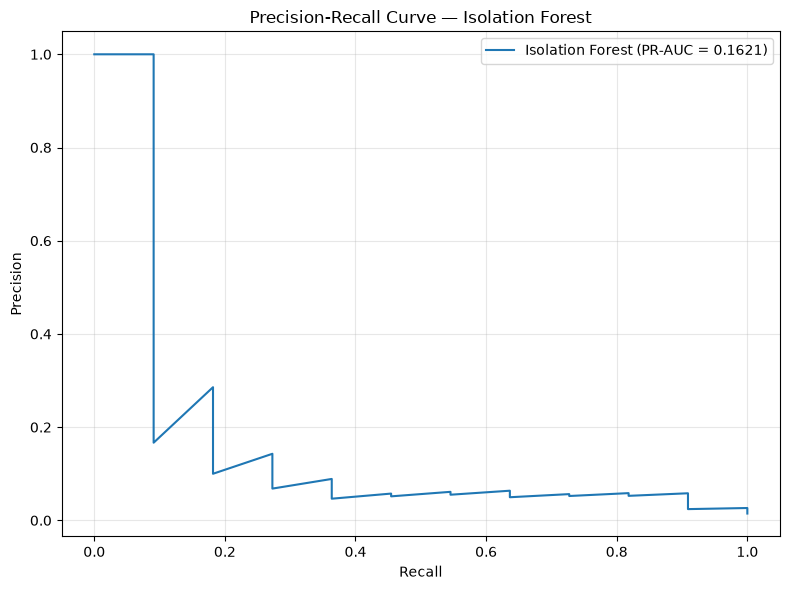


PR curve saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\isolation_forest_pr_curve.png


In [3]:
# --------------------------------------------------
# Step 7.3 — Isolation Forest PR-AUC Evaluation
# --------------------------------------------------

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    auc
)

# --------------------------------------------------
# 1. Validation labels
# --------------------------------------------------

y_validation = validation_results["is_suspicious"].values

# Higher anomaly score = more suspicious
scores_validation = validation_results["anomaly_score"].values

# --------------------------------------------------
# 2. Precision-Recall curve
# --------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_validation,
    scores_validation
)

# Average Precision
average_precision = average_precision_score(
    y_validation,
    scores_validation
)

# Trapezoidal PR-AUC
pr_auc = auc(
    recall[::-1],
    precision[::-1]
)

print("Isolation Forest — Validation Evaluation")
print("=========================================")
print(f"Average Precision (AP): {average_precision:.4f}")
print(f"PR-AUC:                 {pr_auc:.4f}")

# --------------------------------------------------
# 3. Plot PR curve
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Isolation Forest (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Isolation Forest")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# --------------------------------------------------
# 4. Save figure
# --------------------------------------------------

figures_dir = Path("..") / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

pr_curve_file = (
    figures_dir / "isolation_forest_pr_curve.png"
)

plt.savefig(
    pr_curve_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nPR curve saved to:")
print(pr_curve_file.resolve())

In [4]:
# --------------------------------------------------
# Step 7.4 — Isolation Forest Alert Analysis
# --------------------------------------------------

# Top 50 alerts
top_50 = (
    validation_results
    .sort_values("anomaly_score", ascending=False)
    .head(50)
)

# Top 100 alerts
top_100 = (
    validation_results
    .sort_values("anomaly_score", ascending=False)
    .head(100)
)

precision_at_50 = (
    top_50["is_suspicious"].sum() / len(top_50)
)

precision_at_100 = (
    top_100["is_suspicious"].sum() / len(top_100)
)

print("Isolation Forest Alert Analysis")
print("================================")

print(
    f"Precision@50:  "
    f"{precision_at_50:.4f} "
    f"({precision_at_50 * 100:.2f}%)"
)

print(
    f"Precision@100: "
    f"{precision_at_100:.4f} "
    f"({precision_at_100 * 100:.2f}%)"
)

print(
    f"\nSuspicious transactions in validation: "
    f"{y_validation.sum()}"
)

print(
    f"Suspicious transactions in top 50: "
    f"{top_50['is_suspicious'].sum()}"
)

print(
    f"Suspicious transactions in top 100: "
    f"{top_100['is_suspicious'].sum()}"
)

Isolation Forest Alert Analysis
Precision@50:  0.0800 (8.00%)
Precision@100: 0.0600 (6.00%)

Suspicious transactions in validation: 11
Suspicious transactions in top 50: 4
Suspicious transactions in top 100: 6


## Isolation Forest — Initial Findings

The Isolation Forest was trained using only normal historical transactions from the training period. It produced anomaly scores for the validation and test periods, where higher scores represent more suspicious observations.

The validation Precision@50 was **8.00%**, meaning that 4 of the 50 highest-ranked alerts were labeled as suspicious.

This indicates that the Isolation Forest identified some suspicious transactions but also ranked several normal high-value transactions as anomalous. This suggests that transaction magnitude and other numerical outlier characteristics may be influencing the anomaly ranking strongly.

The Isolation Forest result will therefore be treated as a baseline for comparison against the One-Class SVM and PyTorch Autoencoder rather than as the final detector.

In [5]:
# --------------------------------------------------
# Phase 8.1 — Train One-Class SVM
# --------------------------------------------------

from sklearn.svm import OneClassSVM
import joblib

# --------------------------------------------------
# 1. Create One-Class SVM
# --------------------------------------------------

one_class_svm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.02
)

# --------------------------------------------------
# 2. Train ONLY on normal historical transactions
# --------------------------------------------------

one_class_svm.fit(
    X_train_normal_scaled
)

print("One-Class SVM trained successfully.")

# --------------------------------------------------
# 3. Generate anomaly scores
# --------------------------------------------------

# decision_function:
# higher = more normal
# lower = more anomalous
#
# Reverse sign so that:
# higher anomaly_score = more suspicious

ocsvm_validation_scores = (
    -one_class_svm.decision_function(
        X_validation_scaled
    )
)

ocsvm_test_scores = (
    -one_class_svm.decision_function(
        X_test_scaled
    )
)

print("\nAnomaly scores generated.")

print("\nValidation score range:")
print(
    f"Minimum: {ocsvm_validation_scores.min():.4f}"
)
print(
    f"Maximum: {ocsvm_validation_scores.max():.4f}"
)

print("\nTest score range:")
print(
    f"Minimum: {ocsvm_test_scores.min():.4f}"
)
print(
    f"Maximum: {ocsvm_test_scores.max():.4f}"
)

One-Class SVM trained successfully.

Anomaly scores generated.

Validation score range:
Minimum: -1.6630
Maximum: 1.6153

Test score range:
Minimum: -1.6742
Maximum: 1.6153


In [6]:
# --------------------------------------------------
# Phase 8.2 — One-Class SVM Results
# --------------------------------------------------

ocsvm_validation_results = validation_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

ocsvm_validation_results["anomaly_score"] = (
    ocsvm_validation_scores
)

ocsvm_test_results = test_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

ocsvm_test_results["anomaly_score"] = (
    ocsvm_test_scores
)

# Highest score = highest suspicion
ocsvm_validation_results = (
    ocsvm_validation_results
    .sort_values(
        "anomaly_score",
        ascending=False
    )
    .reset_index(drop=True)
)

ocsvm_test_results = (
    ocsvm_test_results
    .sort_values(
        "anomaly_score",
        ascending=False
    )
    .reset_index(drop=True)
)

# --------------------------------------------------
# Precision@50
# --------------------------------------------------

ocsvm_top_50 = (
    ocsvm_validation_results.head(50)
)

ocsvm_precision_at_50 = (
    ocsvm_top_50["is_suspicious"].sum()
    / 50
)

print("One-Class SVM — Validation Alerts")
print("==================================")

print(
    f"Suspicious transactions in top 50: "
    f"{ocsvm_top_50['is_suspicious'].sum()}"
)

print(
    f"Precision@50: "
    f"{ocsvm_precision_at_50:.4f} "
    f"({ocsvm_precision_at_50 * 100:.2f}%)"
)

print("\nHighest-risk validation transactions:")
display(
    ocsvm_top_50.head(10)
)

One-Class SVM — Validation Alerts
Suspicious transactions in top 50: 7
Precision@50: 0.1400 (14.00%)

Highest-risk validation transactions:


,transaction_id,timestamp,customer_id,amount,discount_pct,is_return,is_suspicious,anomaly_score
0,TXN_02731,2026-05-19 23:07:48,CUST_0498,33270.404387,48.352448,0,1,1.615297
1,TXN_01375,2026-05-22 10:09:43,CUST_0107,34547.915993,13.719099,0,0,1.611679
2,TXN_02667,2026-05-09 21:36:33,CUST_0075,591274.131603,6.859366,0,1,1.501993
3,TXN_03084,2026-06-01 19:35:15,CUST_0107,41681.557788,6.086533,0,0,1.423298
4,TXN_01865,2026-06-02 03:00:08,CUST_0107,17668.748425,7.065307,0,0,1.234175
5,TXN_03262,2026-05-24 09:40:20,CUST_0520,156338.026255,3.457928,0,0,0.912804
6,TXN_02809,2026-05-11 05:01:57,CUST_0530,48532.216870,18.014547,0,0,0.905413
7,TXN_04991,2026-05-20 09:29:48,CUST_0115,163319.040596,1.548596,0,0,0.754524
8,TXN_03120,2026-05-12 14:37:36,CUST_0537,125709.441627,8.274606,1,0,0.608122
9,TXN_03383,2026-05-09 21:11:14,CUST_0639,473025.084146,5.200574,0,0,0.388081


One-Class SVM — Validation Evaluation
Average Precision (AP): 0.2701


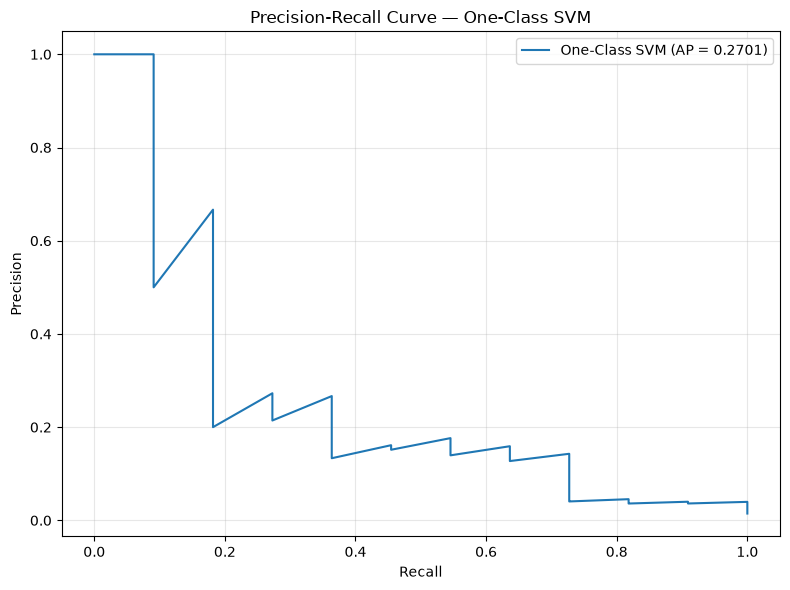


PR curve saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\one_class_svm_pr_curve.png


In [7]:
# --------------------------------------------------
# Phase 8.3 — One-Class SVM PR Evaluation
# --------------------------------------------------

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

y_validation = (
    ocsvm_validation_results["is_suspicious"].values
)

scores_validation = (
    ocsvm_validation_results["anomaly_score"].values
)

precision_ocsvm, recall_ocsvm, thresholds_ocsvm = (
    precision_recall_curve(
        y_validation,
        scores_validation
    )
)

ocsvm_average_precision = (
    average_precision_score(
        y_validation,
        scores_validation
    )
)

print("One-Class SVM — Validation Evaluation")
print("=======================================")
print(
    f"Average Precision (AP): "
    f"{ocsvm_average_precision:.4f}"
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    recall_ocsvm,
    precision_ocsvm,
    label=(
        f"One-Class SVM "
        f"(AP = {ocsvm_average_precision:.4f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Precision-Recall Curve — One-Class SVM"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

ocsvm_pr_curve_file = (
    figures_dir
    / "one_class_svm_pr_curve.png"
)

plt.savefig(
    ocsvm_pr_curve_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nPR curve saved to:")
print(ocsvm_pr_curve_file.resolve())

In [8]:
# --------------------------------------------------
# Phase 8.4 — Save One-Class SVM
# --------------------------------------------------

ocsvm_model_file = (
    models_dir / "one_class_svm.joblib"
)

joblib.dump(
    one_class_svm,
    ocsvm_model_file
)

ocsvm_validation_file = (
    Path("..")
    / "data"
    / "processed"
    / "one_class_svm_validation_scores.csv"
)

ocsvm_test_file = (
    Path("..")
    / "data"
    / "processed"
    / "one_class_svm_test_scores.csv"
)

ocsvm_validation_results.to_csv(
    ocsvm_validation_file,
    index=False
)

ocsvm_test_results.to_csv(
    ocsvm_test_file,
    index=False
)

print("One-Class SVM model saved to:")
print(ocsvm_model_file.resolve())

print("\nValidation scores saved to:")
print(ocsvm_validation_file.resolve())

print("\nTest scores saved to:")
print(ocsvm_test_file.resolve())

One-Class SVM model saved to:
C:\Users\ahmed\Desktop\4th project\models\one_class_svm.joblib

Validation scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\one_class_svm_validation_scores.csv

Test scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\one_class_svm_test_scores.csv


Processed dataset loaded.
Shape: (5000, 20)

Time-based split:
Train: 3500
Validation: 750
Test: 750

Number of model features: 12

Normal training records: 3448
Previously fitted scaler loaded.
PyTorch device: cpu

Autoencoder architecture:
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=12, bias=True)
  )
)

Training Autoencoder...
Epoch 01/50 - Loss: 1.005382
Epoch 10/50 - Loss: 0.330199
Epoch 20/50 - Loss: 0.144067
Epoch 30/50 - Loss: 0.103525
Epoch 40/50 - Loss: 0.090151
Epoch 50/50 - Loss: 0.085067

Autoencoder training completed.


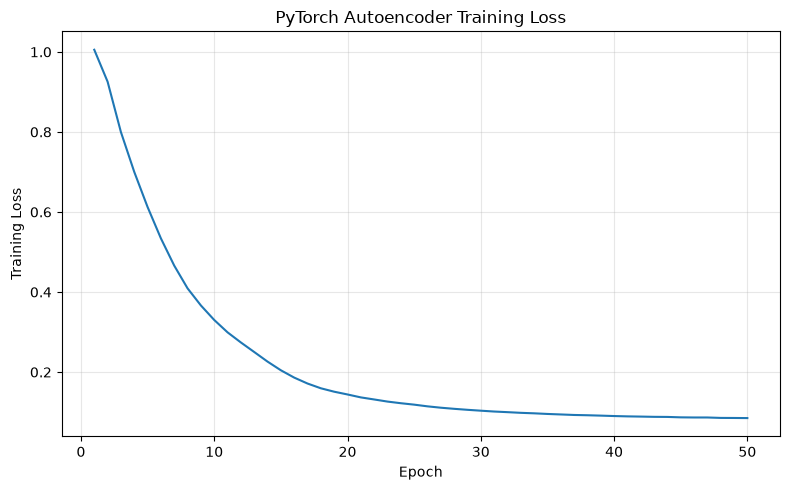


Training-loss chart saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\autoencoder_training_loss.png


In [2]:
# --------------------------------------------------
# Phase 9.1 — PyTorch Autoencoder
# Self-contained version
# --------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

PROJECT_ROOT = Path("..")

processed_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "furniture_workshop_transactions_features.csv"
)

scaler_file = (
    PROJECT_ROOT
    / "models"
    / "feature_scaler.joblib"
)

models_dir = PROJECT_ROOT / "models"
figures_dir = PROJECT_ROOT / "reports" / "figures"

models_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 2. Load processed dataset
# --------------------------------------------------

if not processed_file.exists():
    raise FileNotFoundError(
        f"Processed dataset not found:\n"
        f"{processed_file.resolve()}"
    )

df_features = pd.read_csv(
    processed_file,
    parse_dates=["timestamp"]
)

df_features = (
    df_features
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Processed dataset loaded.")
print("Shape:", df_features.shape)


# --------------------------------------------------
# 3. Recreate the same time-based split
# --------------------------------------------------

n = len(df_features)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = df_features.iloc[:train_end].copy()
validation_df = df_features.iloc[
    train_end:validation_end
].copy()
test_df = df_features.iloc[
    validation_end:
].copy()

print("\nTime-based split:")
print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))


# --------------------------------------------------
# 4. Define exactly the same 12 model features
# --------------------------------------------------

feature_columns = [
    "quantity",
    "unit_price",
    "amount",
    "discount_pct",
    "delivery_distance_km",
    "is_return",
    "customer_tenure_days",
    "transaction_velocity_24h",
    "amount_deviation_from_history",
    "time_of_day_deviation",
    "discount_deviation_from_history",
    "return_frequency_30d"
]

print("\nNumber of model features:", len(feature_columns))


# --------------------------------------------------
# 5. Select normal historical training transactions
# --------------------------------------------------

train_normal_df = train_df[
    train_df["is_suspicious"] == 0
].copy()

print(
    "\nNormal training records:",
    len(train_normal_df)
)


# --------------------------------------------------
# 6. Load previously fitted scaler
# --------------------------------------------------

if not scaler_file.exists():
    raise FileNotFoundError(
        f"Scaler not found:\n"
        f"{scaler_file.resolve()}"
    )

scaler = joblib.load(scaler_file)

print("Previously fitted scaler loaded.")


# --------------------------------------------------
# 7. Prepare feature matrices
# --------------------------------------------------

X_train_normal = (
    train_normal_df[feature_columns]
)

X_train_normal_scaled = scaler.transform(
    X_train_normal
)


# --------------------------------------------------
# 8. Convert training data to PyTorch tensors
# --------------------------------------------------

X_train_tensor = torch.tensor(
    X_train_normal_scaled,
    dtype=torch.float32
)

train_dataset = TensorDataset(
    X_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)


# --------------------------------------------------
# 9. Reproducibility
# --------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)


# --------------------------------------------------
# 10. Select CPU
# --------------------------------------------------

device = torch.device("cpu")

print("PyTorch device:", device)


# --------------------------------------------------
# 11. Define Autoencoder
# --------------------------------------------------

class Autoencoder(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim)
        )

    def forward(self, x):

        encoded = self.encoder(x)

        decoded = self.decoder(encoded)

        return decoded


input_dim = X_train_normal_scaled.shape[1]

autoencoder = Autoencoder(
    input_dim=input_dim
).to(device)

print("\nAutoencoder architecture:")
print(autoencoder)


# --------------------------------------------------
# 12. Loss function and optimizer
# --------------------------------------------------

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    autoencoder.parameters(),
    lr=0.001
)


# --------------------------------------------------
# 13. Train Autoencoder
# --------------------------------------------------

EPOCHS = 50

training_losses = []

print("\nTraining Autoencoder...")
print("=======================")

for epoch in range(EPOCHS):

    autoencoder.train()

    epoch_loss = 0.0

    for batch in train_loader:

        batch_x = batch[0].to(device)

        optimizer.zero_grad()

        reconstructed = autoencoder(
            batch_x
        )

        loss = criterion(
            reconstructed,
            batch_x
        )

        loss.backward()

        optimizer.step()

        epoch_loss += (
            loss.item()
            * batch_x.size(0)
        )

    epoch_loss /= len(
        train_loader.dataset
    )

    training_losses.append(
        epoch_loss
    )

    if (
        (epoch + 1) % 10 == 0
        or epoch == 0
    ):

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} "
            f"- Loss: {epoch_loss:.6f}"
        )


print("\nAutoencoder training completed.")


# --------------------------------------------------
# 14. Plot training loss
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    training_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title(
    "PyTorch Autoencoder Training Loss"
)

plt.grid(alpha=0.3)

plt.tight_layout()


# --------------------------------------------------
# 15. Save training-loss figure
# --------------------------------------------------

autoencoder_loss_file = (
    figures_dir
    / "autoencoder_training_loss.png"
)

plt.savefig(
    autoencoder_loss_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    "\nTraining-loss chart saved to:"
)

print(
    autoencoder_loss_file.resolve()
)

In [3]:
# --------------------------------------------------
# Phase 9.2 — Autoencoder Anomaly Scores
# Self-contained version
# --------------------------------------------------

# --------------------------------------------------
# 1. Load validation and test data
# --------------------------------------------------

X_validation = validation_df[feature_columns].copy()

X_test = test_df[feature_columns].copy()

# Scale using the SAME scaler fitted on normal training data
X_validation_scaled = scaler.transform(
    X_validation
)

X_test_scaled = scaler.transform(
    X_test
)

print("Validation and test features prepared.")


# --------------------------------------------------
# 2. Reconstruction error function
# --------------------------------------------------

def calculate_reconstruction_error(
    model,
    X,
    device="cpu"
):
    """
    Calculate mean squared reconstruction error
    for each transaction.

    Higher error = more anomalous.
    """

    model.eval()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():

        reconstructed = model(X_tensor)

        errors = torch.mean(
            (X_tensor - reconstructed) ** 2,
            dim=1
        )

    return errors.cpu().numpy()


# --------------------------------------------------
# 3. Calculate validation and test scores
# --------------------------------------------------

ae_validation_scores = calculate_reconstruction_error(
    autoencoder,
    X_validation_scaled,
    device
)

ae_test_scores = calculate_reconstruction_error(
    autoencoder,
    X_test_scaled,
    device
)

print("\nAutoencoder anomaly scores generated.")

print("\nValidation score range:")
print(
    f"Minimum: {ae_validation_scores.min():.6f}"
)
print(
    f"Maximum: {ae_validation_scores.max():.6f}"
)

print("\nTest score range:")
print(
    f"Minimum: {ae_test_scores.min():.6f}"
)
print(
    f"Maximum: {ae_test_scores.max():.6f}"
)


# --------------------------------------------------
# 4. Create validation results
# --------------------------------------------------

ae_validation_results = validation_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

ae_validation_results["anomaly_score"] = (
    ae_validation_scores
)


# --------------------------------------------------
# 5. Create test results
# --------------------------------------------------

ae_test_results = test_df[
    [
        "transaction_id",
        "timestamp",
        "customer_id",
        "amount",
        "discount_pct",
        "is_return",
        "is_suspicious"
    ]
].copy()

ae_test_results["anomaly_score"] = (
    ae_test_scores
)


# --------------------------------------------------
# 6. Sort by highest anomaly score
# --------------------------------------------------

ae_validation_results = (
    ae_validation_results
    .sort_values(
        "anomaly_score",
        ascending=False
    )
    .reset_index(drop=True)
)

ae_test_results = (
    ae_test_results
    .sort_values(
        "anomaly_score",
        ascending=False
    )
    .reset_index(drop=True)
)


# --------------------------------------------------
# 7. Precision@50
# --------------------------------------------------

ae_top_50 = (
    ae_validation_results
    .head(50)
)

ae_precision_at_50 = (
    ae_top_50["is_suspicious"].sum()
    / 50
)

print("\nAutoencoder — Validation Alerts")
print("================================")

print(
    f"Suspicious transactions in top 50: "
    f"{ae_top_50['is_suspicious'].sum()}"
)

print(
    f"Precision@50: "
    f"{ae_precision_at_50:.4f} "
    f"({ae_precision_at_50 * 100:.2f}%)"
)

print("\nHighest-risk validation transactions:")

display(
    ae_top_50.head(10)
)

Validation and test features prepared.

Autoencoder anomaly scores generated.

Validation score range:
Minimum: 0.000872
Maximum: 8.082665

Test score range:
Minimum: 0.000691
Maximum: 23.423933

Autoencoder — Validation Alerts
Suspicious transactions in top 50: 5
Precision@50: 0.1000 (10.00%)

Highest-risk validation transactions:


,transaction_id,timestamp,customer_id,amount,discount_pct,is_return,is_suspicious,anomaly_score
0,TXN_01375,2026-05-22 10:09:43,CUST_0107,34547.915993,13.719099,0,0,8.082665
1,TXN_02731,2026-05-19 23:07:48,CUST_0498,33270.404387,48.352448,0,1,5.388134
2,TXN_03084,2026-06-01 19:35:15,CUST_0107,41681.557788,6.086533,0,0,4.490947
3,TXN_04991,2026-05-20 09:29:48,CUST_0115,163319.040596,1.548596,0,0,1.783372
4,TXN_01865,2026-06-02 03:00:08,CUST_0107,17668.748425,7.065307,0,0,1.363321
5,TXN_00882,2026-05-18 14:44:36,CUST_0221,220207.066827,12.580867,0,0,0.956745
6,TXN_03949,2026-06-01 18:02:15,CUST_0301,43110.800195,3.016935,0,0,0.877829
7,TXN_00040,2026-06-03 03:00:00,CUST_0055,36550.752029,1.854161,0,1,0.724056
8,TXN_03383,2026-05-09 21:11:14,CUST_0639,473025.084146,5.200574,0,0,0.707264
9,TXN_04122,2026-05-28 06:00:56,CUST_0565,324768.038729,0.000000,0,0,0.675099


PyTorch Autoencoder — Validation Evaluation
Average Precision (AP): 0.1124


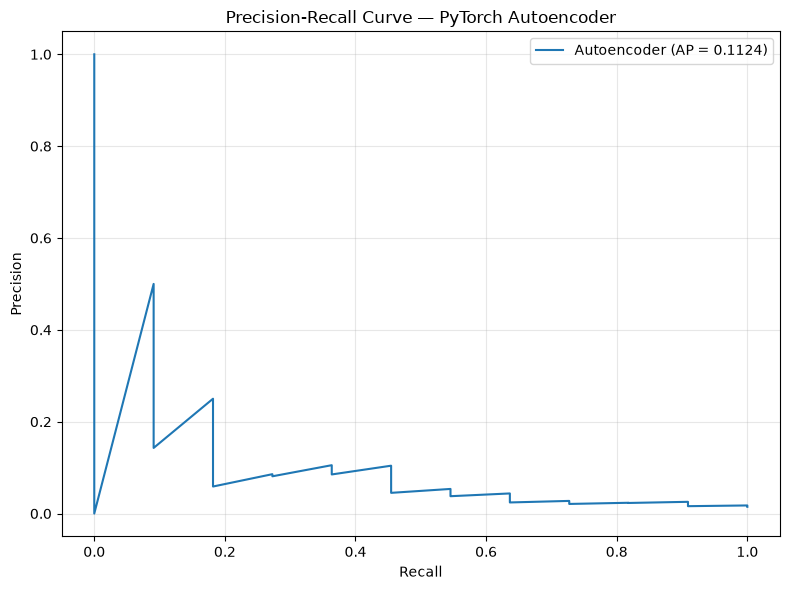


PR curve saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\autoencoder_pr_curve.png


In [4]:
# --------------------------------------------------
# Phase 9.3 — Autoencoder PR Evaluation
# --------------------------------------------------

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Validation labels
y_validation_ae = (
    ae_validation_results["is_suspicious"].values
)

# Higher score = more suspicious
scores_validation_ae = (
    ae_validation_results["anomaly_score"].values
)

# Precision-Recall curve
precision_ae, recall_ae, thresholds_ae = (
    precision_recall_curve(
        y_validation_ae,
        scores_validation_ae
    )
)

# Average Precision
ae_average_precision = (
    average_precision_score(
        y_validation_ae,
        scores_validation_ae
    )
)

print("PyTorch Autoencoder — Validation Evaluation")
print("=============================================")

print(
    f"Average Precision (AP): "
    f"{ae_average_precision:.4f}"
)


# --------------------------------------------------
# Plot PR curve
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    recall_ae,
    precision_ae,
    label=(
        f"Autoencoder "
        f"(AP = {ae_average_precision:.4f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve — PyTorch Autoencoder"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()


# --------------------------------------------------
# Save figure
# --------------------------------------------------

ae_pr_curve_file = (
    figures_dir
    / "autoencoder_pr_curve.png"
)

plt.savefig(
    ae_pr_curve_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nPR curve saved to:")
print(ae_pr_curve_file.resolve())

In [5]:
# --------------------------------------------------
# Phase 9.4 — Save Autoencoder and Results
# --------------------------------------------------

# Save model
autoencoder_model_file = (
    models_dir / "autoencoder.pt"
)

torch.save(
    {
        "model_state_dict": autoencoder.state_dict(),
        "input_dim": input_dim,
        "feature_columns": feature_columns
    },
    autoencoder_model_file
)


# Save validation and test scores
ae_validation_file = (
    Path("..")
    / "data"
    / "processed"
    / "autoencoder_validation_scores.csv"
)

ae_test_file = (
    Path("..")
    / "data"
    / "processed"
    / "autoencoder_test_scores.csv"
)

ae_validation_results.to_csv(
    ae_validation_file,
    index=False
)

ae_test_results.to_csv(
    ae_test_file,
    index=False
)


print("Autoencoder model saved to:")
print(
    autoencoder_model_file.resolve()
)

print("\nValidation scores saved to:")
print(
    ae_validation_file.resolve()
)

print("\nTest scores saved to:")
print(
    ae_test_file.resolve()
)

Autoencoder model saved to:
C:\Users\ahmed\Desktop\4th project\models\autoencoder.pt

Validation scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\autoencoder_validation_scores.csv

Test scores saved to:
C:\Users\ahmed\Desktop\4th project\data\processed\autoencoder_test_scores.csv


In [6]:
# --------------------------------------------------
# Phase 10.1 — Final Model Comparison
# --------------------------------------------------

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    auc
)

# --------------------------------------------------
# 1. Load saved validation scores
# --------------------------------------------------

PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

if_validation_file = (
    PROCESSED_DIR
    / "isolation_forest_validation_scores.csv"
)

ocsvm_validation_file = (
    PROCESSED_DIR
    / "one_class_svm_validation_scores.csv"
)

ae_validation_file = (
    PROCESSED_DIR
    / "autoencoder_validation_scores.csv"
)

required_files = [
    if_validation_file,
    ocsvm_validation_file,
    ae_validation_file
]

for file_path in required_files:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Required validation score file not found:\n"
            f"{file_path.resolve()}"
        )

if_results = pd.read_csv(
    if_validation_file
)

ocsvm_results = pd.read_csv(
    ocsvm_validation_file
)

ae_results = pd.read_csv(
    ae_validation_file
)

# --------------------------------------------------
# 2. Define evaluation function
# --------------------------------------------------

def evaluate_detector(results, model_name):

    y_true = results["is_suspicious"].values

    scores = results["anomaly_score"].values

    # Precision-Recall curve
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            scores
        )
    )

    # Average Precision
    average_precision = (
        average_precision_score(
            y_true,
            scores
        )
    )

    # Trapezoidal PR-AUC
    pr_auc = auc(
        recall[::-1],
        precision[::-1]
    )

    # Precision@50
    top_50 = (
        results
        .sort_values(
            "anomaly_score",
            ascending=False
        )
        .head(50)
    )

    precision_at_50 = (
        top_50["is_suspicious"].sum()
        / 50
    )

    return {
        "Model": model_name,
        "Average Precision": average_precision,
        "PR-AUC": pr_auc,
        "Precision@50": precision_at_50,
        "Suspicious in Top 50": int(
            top_50["is_suspicious"].sum()
        ),
        "Validation Suspicious": int(
            y_true.sum()
        ),
        "Total Validation Records": len(
            y_true
        ),
        "Precision": precision,
        "Recall": recall
    }


# --------------------------------------------------
# 3. Evaluate all three detectors
# --------------------------------------------------

if_metrics = evaluate_detector(
    if_results,
    "Isolation Forest"
)

ocsvm_metrics = evaluate_detector(
    ocsvm_results,
    "One-Class SVM"
)

ae_metrics = evaluate_detector(
    ae_results,
    "PyTorch Autoencoder"
)

all_metrics = [
    if_metrics,
    ocsvm_metrics,
    ae_metrics
]

# --------------------------------------------------
# 4. Create comparison table
# --------------------------------------------------

comparison_table = pd.DataFrame([
    {
        "Model": m["Model"],
        "Average Precision": m["Average Precision"],
        "PR-AUC": m["PR-AUC"],
        "Precision@50": m["Precision@50"],
        "Suspicious in Top 50": m["Suspicious in Top 50"]
    }
    for m in all_metrics
])

print("FINAL VALIDATION MODEL COMPARISON")
print("=================================")

display(
    comparison_table.style.format({
        "Average Precision": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Precision@50": "{:.2%}"
    })
)

# --------------------------------------------------
# 5. Determine best model by PR-AUC
# --------------------------------------------------

best_pr_auc_row = comparison_table.loc[
    comparison_table["PR-AUC"].idxmax()
]

best_p50_row = comparison_table.loc[
    comparison_table["Precision@50"].idxmax()
]

print("\nBest model by PR-AUC:")
print(
    f"{best_pr_auc_row['Model']} "
    f"({best_pr_auc_row['PR-AUC']:.4f})"
)

print("\nBest model by Precision@50:")
print(
    f"{best_p50_row['Model']} "
    f"({best_p50_row['Precision@50']:.2%})"
)

# --------------------------------------------------
# 6. Save comparison table
# --------------------------------------------------

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_file = (
    REPORTS_DIR
    / "model_comparison_validation.csv"
)

comparison_table.to_csv(
    comparison_file,
    index=False
)

print("\nComparison table saved to:")
print(comparison_file.resolve())

FINAL VALIDATION MODEL COMPARISON


,Model,Average Precision,PR-AUC,Precision@50,Suspicious in Top 50
0,Isolation Forest,0.1727,0.1621,8.00%,4
1,One-Class SVM,0.2701,0.2523,14.00%,7
2,PyTorch Autoencoder,0.1124,0.0805,10.00%,5



Best model by PR-AUC:
One-Class SVM (0.2523)

Best model by Precision@50:
One-Class SVM (14.00%)

Comparison table saved to:
C:\Users\ahmed\Desktop\4th project\reports\model_comparison_validation.csv


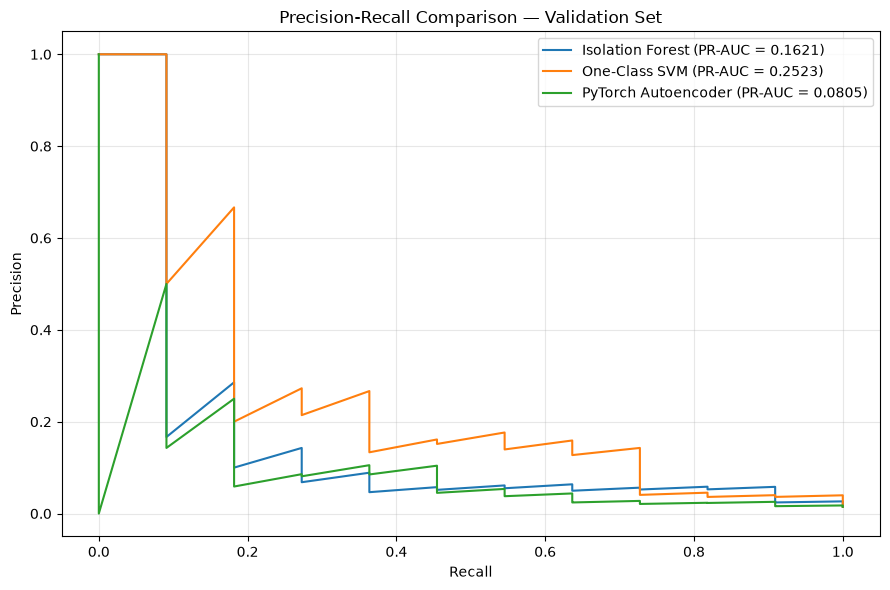

Combined PR curve saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\all_models_pr_curve.png


In [7]:
# --------------------------------------------------
# Phase 10.2 — Combined Precision-Recall Curves
# --------------------------------------------------

plt.figure(figsize=(9, 6))

for metrics in all_metrics:

    plt.plot(
        metrics["Recall"],
        metrics["Precision"],
        label=(
            f"{metrics['Model']} "
            f"(PR-AUC = {metrics['PR-AUC']:.4f})"
        )
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Comparison — Validation Set"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

combined_pr_file = (
    PROJECT_ROOT
    / "reports"
    / "figures"
    / "all_models_pr_curve.png"
)

plt.savefig(
    combined_pr_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Combined PR curve saved to:")
print(combined_pr_file.resolve())

In [8]:
# --------------------------------------------------
# Phase 10.3 — Success Target Check
# --------------------------------------------------

TARGET_PRECISION_AT_50 = 0.25

target_check = comparison_table.copy()

target_check["Target Met"] = (
    target_check["Precision@50"]
    >= TARGET_PRECISION_AT_50
)

print("PRECISION@50 SUCCESS TARGET")
print("============================")

display(
    target_check[
        [
            "Model",
            "Precision@50",
            "Suspicious in Top 50",
            "Target Met"
        ]
    ].style.format({
        "Precision@50": "{:.2%}"
    })
)

PRECISION@50 SUCCESS TARGET


,Model,Precision@50,Suspicious in Top 50,Target Met
0,Isolation Forest,8.00%,4,False
1,One-Class SVM,14.00%,7,False
2,PyTorch Autoencoder,10.00%,5,False


## Phase 10 — Model Comparison

The three anomaly detectors were evaluated on the same time-based validation set using Average Precision, trapezoidal PR-AUC, and Precision@50.

The comparison shows differences in how effectively each detector ranks rare suspicious transactions near the top of the alert list.

Precision@50 is particularly important for the workshop because it approximates the quality of the first 50 alerts that would be prioritized for human review.

The model with the strongest validation performance will be considered for the cost-based threshold analysis in Phase 11.

In [1]:
# --------------------------------------------------
# Phase 11.1 — Cost-Based Threshold Analysis
# One-Class SVM
# --------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Load One-Class SVM validation scores
# --------------------------------------------------

PROJECT_ROOT = Path("..")

ocsvm_validation_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "one_class_svm_validation_scores.csv"
)

if not ocsvm_validation_file.exists():
    raise FileNotFoundError(
        f"Validation score file not found:\n"
        f"{ocsvm_validation_file.resolve()}"
    )

ocsvm_validation_results = pd.read_csv(
    ocsvm_validation_file,
    parse_dates=["timestamp"]
)

# --------------------------------------------------
# 2. Business assumptions
# --------------------------------------------------

MISSED_FRAUD_COST = 25_000
FALSE_ALARM_COST = 500
REVIEW_MINUTES_PER_ALERT = 5

print("BUSINESS COST ASSUMPTIONS")
print("=========================")

print(
    f"Missed fraud cost: "
    f"PKR {MISSED_FRAUD_COST:,}"
)

print(
    f"False-alarm/review cost: "
    f"PKR {FALSE_ALARM_COST:,}"
)

print(
    f"Review time per alert: "
    f"{REVIEW_MINUTES_PER_ALERT} minutes"
)

# --------------------------------------------------
# 3. Prepare labels and anomaly scores
# --------------------------------------------------

y_true = (
    ocsvm_validation_results[
        "is_suspicious"
    ].to_numpy()
)

scores = (
    ocsvm_validation_results[
        "anomaly_score"
    ].to_numpy()
)

# Higher score = more suspicious

# --------------------------------------------------
# 4. Generate candidate thresholds
# --------------------------------------------------

unique_thresholds = np.sort(
    np.unique(scores)
)

# Add thresholds outside observed range
candidate_thresholds = np.concatenate([
    [scores.max() + 1e-9],
    unique_thresholds[::-1],
    [scores.min() - 1e-9]
])

threshold_rows = []

# --------------------------------------------------
# 5. Evaluate every threshold
# --------------------------------------------------

for threshold in candidate_thresholds:

    predictions = (
        scores >= threshold
    ).astype(int)

    tp = int(
        np.sum(
            (predictions == 1)
            & (y_true == 1)
        )
    )

    fp = int(
        np.sum(
            (predictions == 1)
            & (y_true == 0)
        )
    )

    fn = int(
        np.sum(
            (predictions == 0)
            & (y_true == 1)
        )
    )

    alerts = int(
        predictions.sum()
    )

    total_cost = (
        fn * MISSED_FRAUD_COST
        +
        fp * FALSE_ALARM_COST
    )

    threshold_rows.append({
        "Threshold": threshold,
        "Alerts": alerts,
        "True Positives": tp,
        "False Alarms": fp,
        "Missed Fraud": fn,
        "Total Cost (PKR)": total_cost
    })

cost_table = pd.DataFrame(
    threshold_rows
)

# --------------------------------------------------
# 6. Estimate validation period duration
# --------------------------------------------------

validation_start = (
    ocsvm_validation_results[
        "timestamp"
    ].min()
)

validation_end = (
    ocsvm_validation_results[
        "timestamp"
    ].max()
)

validation_days = (
    validation_end - validation_start
).total_seconds() / (24 * 60 * 60)

validation_weeks = (
    validation_days / 7
)

# --------------------------------------------------
# 7. Weekly workload estimates
# --------------------------------------------------

cost_table["Weekly Alerts"] = (
    cost_table["Alerts"]
    / validation_weeks
)

cost_table["Weekly Review Hours"] = (
    cost_table["Weekly Alerts"]
    * REVIEW_MINUTES_PER_ALERT
    / 60
)

# --------------------------------------------------
# 8. Select minimum-cost threshold
# --------------------------------------------------

best_cost = (
    cost_table["Total Cost (PKR)"].min()
)

best_candidates = cost_table[
    cost_table["Total Cost (PKR)"] == best_cost
].copy()

# If multiple thresholds have identical cost,
# select the one generating fewer alerts.
best_row = (
    best_candidates
    .sort_values("Alerts")
    .iloc[0]
)

# --------------------------------------------------
# 9. Display selected threshold
# --------------------------------------------------

print("\nVALIDATION PERIOD")
print("=================")

print(
    f"Start: {validation_start}"
)

print(
    f"End:   {validation_end}"
)

print(
    f"Duration: {validation_days:.2f} days "
    f"({validation_weeks:.2f} weeks)"
)

print("\nSELECTED COST-BASED THRESHOLD")
print("=============================")

print(
    f"Threshold: "
    f"{best_row['Threshold']:.6f}"
)

print(
    f"Alerts: "
    f"{int(best_row['Alerts'])}"
)

print(
    f"True Positives: "
    f"{int(best_row['True Positives'])}"
)

print(
    f"False Alarms: "
    f"{int(best_row['False Alarms'])}"
)

print(
    f"Missed Fraud: "
    f"{int(best_row['Missed Fraud'])}"
)

print(
    f"Total Cost: "
    f"PKR {int(best_row['Total Cost (PKR)']):,}"
)

print(
    f"Estimated Weekly Alerts: "
    f"{best_row['Weekly Alerts']:.2f}"
)

print(
    f"Estimated Weekly Review Hours: "
    f"{best_row['Weekly Review Hours']:.2f}"
)

BUSINESS COST ASSUMPTIONS
Missed fraud cost: PKR 25,000
False-alarm/review cost: PKR 500
Review time per alert: 5 minutes

VALIDATION PERIOD
Start: 2026-05-07 13:35:49
End:   2026-06-03 17:14:48
Duration: 27.15 days (3.88 weeks)

SELECTED COST-BASED THRESHOLD
Threshold: -0.221592
Alerts: 56
True Positives: 8
False Alarms: 48
Missed Fraud: 3
Total Cost: PKR 99,000
Estimated Weekly Alerts: 14.44
Estimated Weekly Review Hours: 1.20


In [2]:
# --------------------------------------------------
# Phase 11.2 — Threshold / Cost Table
# --------------------------------------------------

# Show the 10 lowest-cost threshold choices
lowest_cost_table = (
    cost_table
    .sort_values(
        ["Total Cost (PKR)", "Alerts"]
    )
    .head(10)
    .copy()
)

display(
    lowest_cost_table.style.format({
        "Threshold": "{:.6f}",
        "Weekly Alerts": "{:.2f}",
        "Weekly Review Hours": "{:.2f}",
        "Total Cost (PKR)": "PKR {:,.0f}"
    })
)

,Threshold,Alerts,True Positives,False Alarms,Missed Fraud,Total Cost (PKR),Weekly Alerts,Weekly Review Hours
56,-0.221592,56,8,48,3,"PKR 99,000",14.44,1.20
57,-0.232930,57,8,49,3,"PKR 99,500",14.70,1.22
58,-0.233166,58,8,50,3,"PKR 100,000",14.95,1.25
59,-0.234895,59,8,51,3,"PKR 100,500",15.21,1.27
60,-0.244004,60,8,52,3,"PKR 101,000",15.47,1.29
61,-0.244939,61,8,53,3,"PKR 101,500",15.73,1.31
62,-0.247830,62,8,54,3,"PKR 102,000",15.98,1.33
63,-0.250864,63,8,55,3,"PKR 102,500",16.24,1.35
64,-0.255104,64,8,56,3,"PKR 103,000",16.50,1.37
65,-0.256388,65,8,57,3,"PKR 103,500",16.76,1.40


In [3]:
# --------------------------------------------------
# Phase 11.3 — Save Cost Analysis
# --------------------------------------------------

cost_table_file = (
    PROJECT_ROOT
    / "reports"
    / "threshold_cost_analysis.csv"
)

cost_table.to_csv(
    cost_table_file,
    index=False
)

print("Cost analysis saved to:")
print(cost_table_file.resolve())

Cost analysis saved to:
C:\Users\ahmed\Desktop\4th project\reports\threshold_cost_analysis.csv


## Phase 11 Completion — Cost-Based Threshold Selection

One-Class SVM was selected as the leading candidate based on its validation ranking performance. A cost-based threshold analysis was conducted using explicit business assumptions: PKR 25,000 per missed suspicious transaction, PKR 500 per false alarm, and five minutes of manual review per alert.

The selected validation threshold was **-0.221592**. It generated 56 alerts, including 8 suspicious transactions and 48 false alarms, while missing 3 of the 11 suspicious validation transactions. The resulting estimated cost was PKR 99,000 for the validation period.

The validation period covered approximately 3.88 weeks. Based on this period, the system would generate an estimated 14.44 alerts per week and require approximately 1.20 hours of manual review per week.

These results meet the predefined target of less than 10 review hours per week. However, the 25% Precision@50 target was not achieved by any model. The cost figures are illustrative estimates based on synthetic data and assumed business costs, not verified financial outcomes for an actual workshop.


## Phase 12 — Robustness Testing

The robustness requirement is evaluated using 20 unusual transaction-note inputs, including spelling mistakes, slang, empty values, very long text, unusual whitespace, Unicode characters, control characters, and non-string inputs.

A dedicated preprocessing function will normalize text, handle missing values, remove unsupported control characters, convert non-string inputs to text, and truncate excessively long notes to a maximum of 500 characters.

Each test will record the input scenario, preprocessing action, output length, and whether the input was handled successfully.

**Scope limitation:** The current anomaly detectors use numerical transaction and behavioural features. Transaction notes are not direct model inputs, so these tests assess text-input handling rather than the effect of text on fraud-detection scores.

In [4]:
# --------------------------------------------------
# Phase 12.2 — Test 20 Unusual Transaction-Note Inputs
# --------------------------------------------------

import numpy as np
import pandas as pd
import unicodedata
from pathlib import Path

# --------------------------------------------------
# 1. Robust text preprocessing function
# --------------------------------------------------

def preprocess_transaction_note(value, max_length=500):
    """
    Normalize an unusual transaction note safely.

    Behaviour:
    - Missing values become empty strings.
    - Non-string inputs are converted to text.
    - Unicode text is normalized.
    - Tabs and line breaks become spaces.
    - Non-printable control characters are removed.
    - Repeated whitespace is collapsed.
    - Text is truncated to max_length characters.
    """

    actions = []

    # Handle missing values
    if value is None or (
        isinstance(value, (float, np.floating))
        and np.isnan(value)
    ):
        text = ""
        actions.append("missing_value_replaced_with_empty")

    else:
        # Convert numbers, booleans, etc. to text
        if not isinstance(value, str):
            text = str(value)
            actions.append("non_string_converted_to_text")
        else:
            text = value

        # Normalize Unicode representation
        normalized = unicodedata.normalize("NFKC", text)

        if normalized != text:
            actions.append("unicode_normalized")

        text = normalized

    # Normalize tabs/newlines and remove control characters
    cleaned_chars = []
    control_characters_removed = False
    line_breaks_normalized = False

    for char in text:

        if char in "\t\n\r":
            cleaned_chars.append(" ")
            line_breaks_normalized = True

        elif char.isprintable():
            cleaned_chars.append(char)

        else:
            control_characters_removed = True

    text = "".join(cleaned_chars)

    if line_breaks_normalized:
        actions.append("tabs_or_line_breaks_normalized")

    if control_characters_removed:
        actions.append("control_characters_removed")

    # Collapse repeated spaces and other whitespace
    collapsed = " ".join(text.split())

    if collapsed != text:
        actions.append("whitespace_normalized")

    text = collapsed

    # Limit maximum note length
    if len(text) > max_length:
        text = text[:max_length]
        actions.append(
            f"truncated_to_{max_length}_characters"
        )

    # Record empty inputs
    if text == "" and not actions:
        actions.append("empty_input")

    if not actions:
        actions.append("unchanged")

    return text, "; ".join(actions)


# --------------------------------------------------
# 2. Define exactly 20 unusual inputs
# --------------------------------------------------

unusual_inputs = [
    ("Typo / misspelling", "Urgnt sofa ordrr, pls delver"),
    ("Slang", "pls delvr ASAP lol, customer needs sofa"),
    ("Empty string", ""),
    ("Whitespace-only", " \t \n   "),
    ("Python None", None),
    ("NaN missing value", np.nan),
    ("Very long text", "urgent furniture request " * 600),
    ("Tabs and newlines", "Order\tneeds\nurgent\r\ndelivery"),
    ("Repeated characters", "soooooooofaaaaaa!!!!!!"),
    ("Punctuation only", "!!!???...;;;---"),
    ("Emoji-heavy note", "🛋️🚚🔥 ASAP 🙌"),
    ("Urdu text", "نیا صوفہ جلدی پہنچائیں"),
    ("Mixed-language text", "Sofa صوفہ chair کرسی ASAP"),
    ("Numeric input", 123456789),
    ("Boolean input", False),
    ("Unicode combining accents", "Cafe\u0301 delivery — très urgent"),
    ("Control characters", "Order\x00chair\x07confirmed"),
    ("Zero-width characters", "\u200bUrgent\u200b sofa"),
    ("HTML-like text", "<b>urgent</b> & sofa order"),
    ("SQL-like text", "' OR '1'='1'; DROP TABLE transactions; --")
]

assert len(unusual_inputs) == 20, "Expected exactly 20 test inputs."


# --------------------------------------------------
# 3. Run tests and record results
# --------------------------------------------------

test_records = []

for test_id, (scenario, raw_input) in enumerate(
    unusual_inputs,
    start=1
):

    cleaned_text, actions = preprocess_transaction_note(
        raw_input,
        max_length=500
    )

    # Create a safe preview without printing huge inputs
    if raw_input is None:
        input_preview = "None"

    elif isinstance(raw_input, (float, np.floating)) and np.isnan(raw_input):
        input_preview = "NaN"

    else:
        input_preview = str(raw_input)
        input_preview = (
            input_preview
            .replace("\n", "\\n")
            .replace("\r", "\\r")
            .replace("\t", "\\t")
        )

        if len(input_preview) > 70:
            input_preview = input_preview[:67] + "..."

    # Determine original input length safely
    if raw_input is None or (
        isinstance(raw_input, (float, np.floating))
        and np.isnan(raw_input)
    ):
        input_length = 0
    else:
        input_length = len(str(raw_input))

    # Validation checks
    passed = (
        isinstance(cleaned_text, str)
        and len(cleaned_text) <= 500
        and "\n" not in cleaned_text
        and "\r" not in cleaned_text
        and "\t" not in cleaned_text
        and all(
            char.isprintable()
            for char in cleaned_text
        )
    )

    test_records.append({
        "Test ID": test_id,
        "Scenario": scenario,
        "Input Type": type(raw_input).__name__,
        "Input Preview": input_preview,
        "Input Length": input_length,
        "Output Length": len(cleaned_text),
        "Actions Taken": actions,
        "Output Preview": cleaned_text[:70],
        "Passed": bool(passed)
    })


# --------------------------------------------------
# 4. Display test report
# --------------------------------------------------

robustness_results = pd.DataFrame(test_records)

print("ROBUSTNESS TEST REPORT")
print("======================")
print("Total tests:", len(robustness_results))
print("Passed:", int(robustness_results["Passed"].sum()))
print("Failed:", int((~robustness_results["Passed"]).sum()))

display(robustness_results)

# Fail visibly if any test failed
assert robustness_results["Passed"].all(), (
    "One or more robustness tests failed. "
    "Inspect the report before continuing."
)

print("\nAll 20 unusual-input tests passed.")


# --------------------------------------------------
# 5. Save report
# --------------------------------------------------

reports_dir = Path("..") / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

robustness_report_file = (
    reports_dir / "robustness_test_results.csv"
)

robustness_results.to_csv(
    robustness_report_file,
    index=False
)

print("\nRobustness report saved to:")
print(robustness_report_file.resolve())

ROBUSTNESS TEST REPORT
Total tests: 20
Passed: 20
Failed: 0


,Test ID,Scenario,Input Type,Input Preview,Input Length,Output Length,Actions Taken,Output Preview,Passed
0,1,Typo / misspelling,str,"Urgnt sofa ordrr, pls delver",28,28,unchanged,"Urgnt sofa ordrr, pls delver",True
1,2,Slang,str,"pls delvr ASAP lol, customer needs sofa",39,39,unchanged,"pls delvr ASAP lol, customer needs sofa",True
2,3,Empty string,str,,0,0,empty_input,,True
3,4,Whitespace-only,str,\t \n,7,0,tabs_or_line_breaks_normalized; whitespace_nor...,,True
4,5,Python None,NoneType,None,0,0,missing_value_replaced_with_empty,,True
5,6,NaN missing value,float,NaN,0,0,missing_value_replaced_with_empty,,True
6,7,Very long text,str,urgent furniture request urgent furniture requ...,15000,500,whitespace_normalized; truncated_to_500_charac...,urgent furniture request urgent furniture requ...,True
7,8,Tabs and newlines,str,Order\tneeds\nurgent\r\ndelivery,28,27,tabs_or_line_breaks_normalized; whitespace_nor...,Order needs urgent delivery,True
8,9,Repeated characters,str,soooooooofaaaaaa!!!!!!,22,22,unchanged,soooooooofaaaaaa!!!!!!,True
9,10,Punctuation only,str,!!!???...;;;---,15,15,unchanged,!!!???...;;;---,True



All 20 unusual-input tests passed.

Robustness report saved to:
C:\Users\ahmed\Desktop\4th project\reports\robustness_test_results.csv


In [5]:
# --------------------------------------------------
# Phase 12.3 — Create Reusable Robustness Module
# --------------------------------------------------

from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd

src_dir = Path("..") / "src"
src_dir.mkdir(parents=True, exist_ok=True)

module_path = src_dir / "robustness.py"

module_source = r'''
"""Robust preprocessing for unusual transaction-note inputs."""

import numpy as np
import unicodedata


def preprocess_transaction_note(value, max_length=500):
    """
    Safely preprocess an unusual transaction note.

    Returns:
        tuple: (cleaned_text, actions_taken)
    """

    if not isinstance(max_length, int) or max_length < 0:
        raise ValueError("max_length must be a non-negative integer.")

    actions = []

    # Handle missing values
    if value is None or (
        isinstance(value, (float, np.floating))
        and np.isnan(value)
    ):
        text = ""
        actions.append("missing_value_replaced_with_empty")
    else:
        if not isinstance(value, str):
            text = str(value)
            actions.append("non_string_converted_to_text")
        else:
            text = value

        # Normalize Unicode
        normalized = unicodedata.normalize("NFKC", text)

        if normalized != text:
            actions.append("unicode_normalized")

        text = normalized

    # Normalize line breaks and remove control characters
    cleaned_chars = []
    control_characters_removed = False
    line_breaks_normalized = False

    for char in text:
        if char in "\t\n\r":
            cleaned_chars.append(" ")
            line_breaks_normalized = True
        elif char.isprintable():
            cleaned_chars.append(char)
        else:
            control_characters_removed = True

    text = "".join(cleaned_chars)

    if line_breaks_normalized:
        actions.append("tabs_or_line_breaks_normalized")

    if control_characters_removed:
        actions.append("control_characters_removed")

    # Collapse repeated whitespace
    collapsed = " ".join(text.split())

    if collapsed != text:
        actions.append("whitespace_normalized")

    text = collapsed

    # Enforce maximum note length
    if len(text) > max_length:
        text = text[:max_length]
        actions.append(f"truncated_to_{max_length}_characters")

    if text == "" and not actions:
        actions.append("empty_input")

    if not actions:
        actions.append("unchanged")

    return text, "; ".join(actions)
'''

module_path.write_text(module_source, encoding="utf-8")

print("Robustness module created:")
print(module_path.resolve())

# Import the module from src/
resolved_src = str(src_dir.resolve())

if resolved_src not in sys.path:
    sys.path.insert(0, resolved_src)

importlib.invalidate_caches()

if "robustness" in sys.modules:
    del sys.modules["robustness"]

import robustness

# Verify the reusable function against the same 20 inputs
module_test_records = []

for test_id, (scenario, raw_input) in enumerate(
    unusual_inputs, start=1
):
    cleaned, actions = robustness.preprocess_transaction_note(
        raw_input,
        max_length=500
    )

    passed = (
        isinstance(cleaned, str)
        and len(cleaned) <= 500
        and all(char.isprintable() for char in cleaned)
        and "\n" not in cleaned
        and "\r" not in cleaned
        and "\t" not in cleaned
    )

    module_test_records.append({
        "Test ID": test_id,
        "Scenario": scenario,
        "Output Length": len(cleaned),
        "Actions Taken": actions,
        "Passed": bool(passed)
    })

module_test_results = pd.DataFrame(module_test_records)

print("\nReusable module verification")
print("============================")
print("Total tests:", len(module_test_results))
print("Passed:", int(module_test_results["Passed"].sum()))
print("Failed:", int((~module_test_results["Passed"]).sum()))

assert module_test_results["Passed"].all()
assert len(module_test_results) == 20

print("\nReusable robustness module verified successfully.")

Robustness module created:
C:\Users\ahmed\Desktop\4th project\src\robustness.py

Reusable module verification
Total tests: 20
Passed: 20
Failed: 0

Reusable robustness module verified successfully.


## Phase 12 Completion — Robustness Testing

The system was tested against 20 unusual transaction-note inputs, including spelling mistakes, slang, empty values, missing values, whitespace variations, very long text, Unicode characters, emojis, control characters, and HTML-like or SQL-like strings.

All 20 tests passed, with zero failures. The preprocessing function handles missing values, converts non-string inputs to text, normalizes Unicode and whitespace, removes non-printable control characters, and truncates notes to a maximum of 500 characters.

The results were recorded in `reports/robustness_test_results.csv`, and the reusable preprocessing function was added to `src/robustness.py`.

**Limitation:** The three anomaly detectors use numerical transaction and behavioural features. Transaction notes are not direct model inputs, so these tests validate text preprocessing robustness rather than proving that text-based fraud detection works. The SQL-like and HTML-like strings were treated as ordinary text and were not executed.

The robustness requirement of 20 unusual-input tests was satisfied.


In [6]:
# --------------------------------------------------
# Update CHANGELOG.md
# --------------------------------------------------

from pathlib import Path

changelog_path = Path("..") / "CHANGELOG.md"

phase12_entry = """
## Phase 12 — Robustness Testing
- Tested 20 unusual transaction-note inputs.
- Achieved 20/20 passing tests with zero failures.
- Added reusable text preprocessing to `src/robustness.py`.
- Saved robustness evidence to `reports/robustness_test_results.csv`.
- Documented the limitation that transaction notes are not direct model inputs.
"""

existing_changelog = (
    changelog_path.read_text(encoding="utf-8")
    if changelog_path.exists()
    else "# Changelog\n"
)

if "## Phase 12 — Robustness Testing" not in existing_changelog:
    with changelog_path.open("a", encoding="utf-8") as file:
        file.write("\n" + phase12_entry + "\n")

print("Changelog updated:")
print(changelog_path.resolve())

Changelog updated:
C:\Users\ahmed\Desktop\4th project\CHANGELOG.md


In [7]:
# --------------------------------------------------
# Phase 13.1 — Project Integrity Audit
# --------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
SRC_DIR = PROJECT_ROOT / "src"

# --------------------------------------------------
# 1. Check required project files
# --------------------------------------------------

required_files = [
    PROJECT_ROOT / "README.md",
    PROJECT_ROOT / "CHANGELOG.md",
    PROJECT_ROOT / "requirements.txt",
    PROJECT_ROOT / ".gitignore",
    RAW_DIR / "furniture_workshop_transactions.csv",
    PROCESSED_DIR / "furniture_workshop_transactions_features.csv",
    MODELS_DIR / "feature_scaler.joblib",
    MODELS_DIR / "isolation_forest.joblib",
    MODELS_DIR / "one_class_svm.joblib",
    MODELS_DIR / "autoencoder.pt",
    REPORTS_DIR / "model_comparison_validation.csv",
    REPORTS_DIR / "threshold_cost_analysis.csv",
    REPORTS_DIR / "robustness_test_results.csv",
    SRC_DIR / "robustness.py",
    FIGURES_DIR / "all_models_pr_curve.png",
    FIGURES_DIR / "isolation_forest_pr_curve.png",
    FIGURES_DIR / "one_class_svm_pr_curve.png",
    FIGURES_DIR / "autoencoder_pr_curve.png",
    FIGURES_DIR / "autoencoder_training_loss.png",
]

file_audit = pd.DataFrame([
    {
        "File": str(path.relative_to(PROJECT_ROOT)),
        "Exists": path.is_file()
    }
    for path in required_files
])

print("REQUIRED FILE AUDIT")
print("===================")
display(file_audit)

missing_files = file_audit.loc[
    ~file_audit["Exists"], "File"
].tolist()

print("\nMissing files:", len(missing_files))

if missing_files:
    for file_name in missing_files:
        print(" -", file_name)
else:
    print("All checked files exist.")


# --------------------------------------------------
# 2. Load and validate the engineered dataset
# --------------------------------------------------

processed_file = (
    PROCESSED_DIR
    / "furniture_workshop_transactions_features.csv"
)

df_audit = pd.read_csv(
    processed_file,
    parse_dates=["timestamp"]
)

df_audit = (
    df_audit
    .sort_values("timestamp")
    .reset_index(drop=True)
)

behavioural_features = [
    "transaction_velocity_24h",
    "amount_deviation_from_history",
    "time_of_day_deviation",
    "discount_deviation_from_history",
    "return_frequency_30d"
]

feature_columns = [
    "quantity",
    "unit_price",
    "amount",
    "discount_pct",
    "delivery_distance_km",
    "is_return",
    "customer_tenure_days",
    *behavioural_features
]

quality_checks = {
    "Exactly 5000 records": len(df_audit) == 5000,
    "Exactly 20 columns": len(df_audit.columns) == 20,
    "Exactly 75 suspicious labels": (
        int(df_audit["is_suspicious"].sum()) == 75
    ),
    "Suspicious rate below 2%": (
        df_audit["is_suspicious"].mean() < 0.02
    ),
    "No duplicate transaction IDs": (
        not df_audit["transaction_id"].duplicated().any()
    ),
    "No missing behavioural features": (
        not df_audit[behavioural_features].isnull().any().any()
    ),
    "Finite numerical model features": (
        np.isfinite(
            df_audit[feature_columns].to_numpy(dtype=float)
        ).all()
    ),
    "Label excluded from model features": (
        "is_suspicious" not in feature_columns
    ),
    "All five behavioural features present": (
        all(f in df_audit.columns for f in behavioural_features)
    ),
}

# --------------------------------------------------
# 3. Recreate chronological split and verify
# --------------------------------------------------

n = len(df_audit)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

audit_train = df_audit.iloc[:train_end].copy()
audit_validation = df_audit.iloc[train_end:validation_end].copy()
audit_test = df_audit.iloc[validation_end:].copy()

quality_checks.update({
    "Train size is 3500": len(audit_train) == 3500,
    "Validation size is 750": len(audit_validation) == 750,
    "Test size is 750": len(audit_test) == 750,
    "Train precedes validation": (
        audit_train["timestamp"].max()
        < audit_validation["timestamp"].min()
    ),
    "Validation precedes test": (
        audit_validation["timestamp"].max()
        < audit_test["timestamp"].min()
    ),
    "All 75 labels retained across splits": (
        audit_train["is_suspicious"].sum()
        + audit_validation["is_suspicious"].sum()
        + audit_test["is_suspicious"].sum()
        == 75
    ),
})

print("\nDATASET / SPLIT CHECKS")
print("======================")
print(f"Train: {len(audit_train)} records, "
      f"{audit_train['is_suspicious'].sum()} suspicious")
print(f"Validation: {len(audit_validation)} records, "
      f"{audit_validation['is_suspicious'].sum()} suspicious")
print(f"Test: {len(audit_test)} records, "
      f"{audit_test['is_suspicious'].sum()} suspicious")


# --------------------------------------------------
# 4. Verify saved score files match each time split
# --------------------------------------------------

score_files = {
    "Isolation Forest": (
        "isolation_forest_validation_scores.csv",
        "isolation_forest_test_scores.csv"
    ),
    "One-Class SVM": (
        "one_class_svm_validation_scores.csv",
        "one_class_svm_test_scores.csv"
    ),
    "PyTorch Autoencoder": (
        "autoencoder_validation_scores.csv",
        "autoencoder_test_scores.csv"
    ),
}

for model_name, (val_filename, test_filename) in score_files.items():

    val_path = PROCESSED_DIR / val_filename
    test_path = PROCESSED_DIR / test_filename

    if val_path.exists() and test_path.exists():

        val_scores = pd.read_csv(val_path)
        test_scores = pd.read_csv(test_path)

        quality_checks[
            f"{model_name}: 750 validation scores"
        ] = len(val_scores) == 750

        quality_checks[
            f"{model_name}: 750 test scores"
        ] = len(test_scores) == 750

        quality_checks[
            f"{model_name}: validation IDs match split"
        ] = set(val_scores["transaction_id"]) == set(
            audit_validation["transaction_id"]
        )

        quality_checks[
            f"{model_name}: test IDs match split"
        ] = set(test_scores["transaction_id"]) == set(
            audit_test["transaction_id"]
        )

    else:
        quality_checks[
            f"{model_name}: score files exist"
        ] = False


# --------------------------------------------------
# 5. Verify robustness evidence
# --------------------------------------------------

robustness_file = (
    REPORTS_DIR / "robustness_test_results.csv"
)

if robustness_file.exists():

    robustness_audit = pd.read_csv(robustness_file)

    passed_values = (
        robustness_audit["Passed"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1"])
    )

    quality_checks["Exactly 20 robustness tests"] = (
        len(robustness_audit) == 20
    )

    quality_checks["All robustness tests passed"] = (
        len(robustness_audit) == 20
        and passed_values.all()
    )

else:
    quality_checks["Robustness evidence exists"] = False


# --------------------------------------------------
# 6. Print final audit summary
# --------------------------------------------------

audit_summary = pd.DataFrame([
    {
        "Check": check,
        "Status": "PASS" if result else "FAIL"
    }
    for check, result in quality_checks.items()
])

print("\nFINAL INTEGRITY AUDIT")
print("=====================")
display(audit_summary)

passed_count = sum(quality_checks.values())
failed_count = len(quality_checks) - passed_count

print("\nPassed:", passed_count)
print("Failed:", failed_count)

if failed_count == 0 and len(missing_files) == 0:
    print("\nIntegrity audit: ALL CHECKS PASSED")
else:
    print("\nIntegrity audit: ISSUES REQUIRE REVIEW")
    print("Review the FAIL statuses and missing-file list above.")

REQUIRED FILE AUDIT


,File,Exists
0,README.md,True
1,CHANGELOG.md,True
2,requirements.txt,True
3,.gitignore,True
4,data\raw\furniture_workshop_transactions.csv,True
5,data\processed\furniture_workshop_transactions...,True
6,models\feature_scaler.joblib,True
7,models\isolation_forest.joblib,True
8,models\one_class_svm.joblib,True
9,models\autoencoder.pt,True



Missing files: 0
All checked files exist.

DATASET / SPLIT CHECKS
Train: 3500 records, 52 suspicious
Validation: 750 records, 11 suspicious
Test: 750 records, 12 suspicious

FINAL INTEGRITY AUDIT


,Check,Status
0,Exactly 5000 records,PASS
1,Exactly 20 columns,PASS
2,Exactly 75 suspicious labels,PASS
3,Suspicious rate below 2%,PASS
4,No duplicate transaction IDs,PASS
5,No missing behavioural features,PASS
6,Finite numerical model features,PASS
7,Label excluded from model features,PASS
8,All five behavioural features present,PASS
9,Train size is 3500,PASS



Passed: 29
Failed: 0

Integrity audit: ALL CHECKS PASSED


In [8]:
# --------------------------------------------------
# Phase 13.2 — Final Test-Set Evaluation
# One-Class SVM
# --------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Load validation-selected threshold
# --------------------------------------------------

cost_file = REPORTS_DIR / "threshold_cost_analysis.csv"

if not cost_file.exists():
    raise FileNotFoundError(
        f"Cost analysis file not found: {cost_file.resolve()}"
    )

saved_cost_table = pd.read_csv(cost_file)

minimum_cost = saved_cost_table["Total Cost (PKR)"].min()

best_candidates = saved_cost_table[
    saved_cost_table["Total Cost (PKR)"] == minimum_cost
].copy()

best_row = (
    best_candidates
    .sort_values("Alerts")
    .iloc[0]
)

selected_threshold = float(best_row["Threshold"])

print("Threshold selected using validation data:")
print(f"{selected_threshold:.6f}")

# --------------------------------------------------
# 2. Load reserved test scores
# --------------------------------------------------

test_scores_file = (
    PROCESSED_DIR / "one_class_svm_test_scores.csv"
)

if not test_scores_file.exists():
    raise FileNotFoundError(
        f"Test scores not found: {test_scores_file.resolve()}"
    )

test_results = pd.read_csv(
    test_scores_file,
    parse_dates=["timestamp"]
)

required_columns = {
    "transaction_id",
    "timestamp",
    "is_suspicious",
    "anomaly_score"
}

if not required_columns.issubset(test_results.columns):
    raise ValueError(
        f"Test file must contain: {sorted(required_columns)}"
    )

if len(test_results) != 750:
    raise ValueError(
        f"Expected 750 test records, found {len(test_results)}."
    )

if test_results["transaction_id"].duplicated().any():
    raise ValueError("Duplicate transaction IDs found in test scores.")

if test_results[list(required_columns - {"transaction_id"})].isnull().any().any():
    raise ValueError("Missing values found in required test columns.")

# --------------------------------------------------
# 3. Apply the fixed threshold — do not retune it
# --------------------------------------------------

y_true = test_results["is_suspicious"].astype(int).to_numpy()
scores = test_results["anomaly_score"].astype(float).to_numpy()

if not np.isfinite(scores).all():
    raise ValueError("Test anomaly scores contain non-finite values.")

y_pred = (scores >= selected_threshold).astype(int)

# --------------------------------------------------
# 4. Classification metrics
# --------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()

test_ap = average_precision_score(y_true, scores)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    scores
)

test_pr_auc = auc(
    recall_curve[::-1],
    precision_curve[::-1]
)

# Top 50 alerts
top_50 = test_results.nlargest(50, "anomaly_score")

precision_at_50 = (
    top_50["is_suspicious"].sum() / 50
)

test_precision = precision_score(
    y_true, y_pred, zero_division=0
)

test_recall = recall_score(
    y_true, y_pred, zero_division=0
)

test_f1 = f1_score(
    y_true, y_pred, zero_division=0
)

# --------------------------------------------------
# 5. Cost and workload using existing assumptions
# --------------------------------------------------

MISSED_FRAUD_COST = 25_000
FALSE_ALARM_COST = 500
REVIEW_MINUTES_PER_ALERT = 5

test_alerts = int(y_pred.sum())

test_cost = (
    fn * MISSED_FRAUD_COST
    + fp * FALSE_ALARM_COST
)

test_start = test_results["timestamp"].min()
test_end = test_results["timestamp"].max()

test_days = (
    test_end - test_start
).total_seconds() / (24 * 60 * 60)

test_weeks = test_days / 7

weekly_alerts = (
    test_alerts / test_weeks
    if test_weeks > 0 else np.nan
)

weekly_review_hours = (
    weekly_alerts * REVIEW_MINUTES_PER_ALERT / 60
    if test_weeks > 0 else np.nan
)

# --------------------------------------------------
# 6. Display final test results
# --------------------------------------------------

print("\nFINAL TEST-SET RESULTS")
print("======================")
print("Test records:", len(test_results))
print("Actual suspicious records:", int(y_true.sum()))
print("Selected threshold:", f"{selected_threshold:.6f}")

print("\nRanking metrics:")
print(f"Average Precision (AP): {test_ap:.4f}")
print(f"Trapezoidal PR-AUC:     {test_pr_auc:.4f}")
print(f"Precision@50:           {precision_at_50:.2%}")

print("\nThreshold metrics:")
print(f"Alerts generated:       {test_alerts}")
print(f"True positives:         {tp}")
print(f"False alarms:           {fp}")
print(f"Missed suspicious:      {fn}")
print(f"True negatives:         {tn}")
print(f"Precision:              {test_precision:.2%}")
print(f"Recall:                 {test_recall:.2%}")
print(f"F1-score:               {test_f1:.4f}")

print("\nEstimated test-period cost:")
print(f"Total assumed cost: PKR {test_cost:,}")
print(f"Test period: {test_days:.2f} days ({test_weeks:.2f} weeks)")
print(f"Estimated weekly alerts: {weekly_alerts:.2f}")
print(f"Estimated weekly review hours: {weekly_review_hours:.2f}")

# --------------------------------------------------
# 7. Save individual test predictions
# --------------------------------------------------

test_predictions = test_results.copy()
test_predictions["predicted_suspicious"] = y_pred
test_predictions["selected_threshold"] = selected_threshold

predictions_file = (
    PROCESSED_DIR / "one_class_svm_test_predictions.csv"
)

test_predictions.to_csv(predictions_file, index=False)

# Save a compact final metric summary
final_metrics = pd.DataFrame([{
    "Model": "One-Class SVM",
    "Threshold": selected_threshold,
    "Test Records": len(test_results),
    "Actual Suspicious": int(y_true.sum()),
    "Average Precision": test_ap,
    "PR-AUC": test_pr_auc,
    "Precision@50": precision_at_50,
    "Alerts": test_alerts,
    "True Positives": int(tp),
    "False Alarms": int(fp),
    "Missed Fraud": int(fn),
    "Total Assumed Cost (PKR)": int(test_cost),
    "Estimated Weekly Alerts": weekly_alerts,
    "Estimated Weekly Review Hours": weekly_review_hours
}])

metrics_file = REPORTS_DIR / "final_test_evaluation.csv"
final_metrics.to_csv(metrics_file, index=False)

print("\nSaved test predictions to:")
print(predictions_file.resolve())

print("\nSaved final test metrics to:")
print(metrics_file.resolve())

Threshold selected using validation data:
-0.221592

FINAL TEST-SET RESULTS
Test records: 750
Actual suspicious records: 12
Selected threshold: -0.221592

Ranking metrics:
Average Precision (AP): 0.4319
Trapezoidal PR-AUC:     0.4286
Precision@50:           10.00%

Threshold metrics:
Alerts generated:       52
True positives:         5
False alarms:           47
Missed suspicious:      7
True negatives:         691
Precision:              9.62%
Recall:                 41.67%
F1-score:               0.1562

Estimated test-period cost:
Total assumed cost: PKR 198,500
Test period: 27.25 days (3.89 weeks)
Estimated weekly alerts: 13.36
Estimated weekly review hours: 1.11

Saved test predictions to:
C:\Users\ahmed\Desktop\4th project\data\processed\one_class_svm_test_predictions.csv

Saved final test metrics to:
C:\Users\ahmed\Desktop\4th project\reports\final_test_evaluation.csv


In [9]:
# --------------------------------------------------
# Phase 13.4 — Save Validation Findings and Fixes
# --------------------------------------------------

from pathlib import Path

PROJECT_ROOT = Path("..")
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

validation_report = """# Week 4 — Final Validation Findings

## 1. Dataset and Integrity Checks

- Total records: 5,000
- Suspicious records: 75 (1.50%)
- Training records: 3,500
- Validation records: 750
- Test records: 750
- Integrity audit: 29 checks passed, 0 failures
- Required project files: all checked files present
- Robustness validation: 20/20 tests passed

## 2. Final Test Evaluation — One-Class SVM

The One-Class SVM was selected based on validation performance.
Its threshold was chosen using the validation data and held fixed
during final test evaluation.

- Selected threshold: -0.221592
- Test records: 750
- Actual suspicious records: 12
- Average Precision: 0.4319
- Trapezoidal PR-AUC: 0.4286
- Precision@50: 10.00%
- Alerts generated: 52
- True positives: 5
- False alarms: 47
- Missed suspicious transactions: 7
- True negatives: 691
- Precision at selected threshold: 9.62%
- Recall at selected threshold: 41.67%
- F1-score: 0.1562

## 3. Illustrative Business Cost

Assumptions:
- Cost per missed suspicious transaction: PKR 25,000
- Cost per false alarm: PKR 500
- Review time per alert: 5 minutes

Test-period estimated cost:
- Missed-event cost: PKR 175,000
- False-alarm cost: PKR 23,500
- Total assumed cost: PKR 198,500

Estimated weekly workload:
- 13.36 alerts per week
- Approximately 1.11 review hours per week

These figures are estimates on synthetic data using assumed costs,
not actual financial outcomes from a real workshop.

## 4. Problems Found and Fixes Applied

### Issue 1: Immutable timestamp array
- Problem: Timestamp modification failed because pandas returned
  an immutable DatetimeIndex.
- Fix: Converted timestamps to a mutable NumPy array before
  modifying selected transaction times.

### Issue 2: Grouped feature engineering lost customer_id
- Problem: The groupby.apply approach removed the grouping column
  under the installed pandas behaviour.
- Fix: Replaced the approach with explicit per-customer processing
  and assignment back to the original dataframe indexes.

### Issue 3: Notebook kernel state was not available
- Problem: A notebook cell failed because NumPy was not imported
  in the active kernel.
- Fix: Made the Autoencoder training cell self-contained, loading
  the processed dataset and saved scaler and declaring imports
  explicitly.

## 5. Limitations and Follow-Up Improvements

- The data is synthetic; results do not establish performance on
  real workshop transactions.
- The predefined Precision@50 target of 25% was not achieved.
- Only 12 suspicious records occur in the test set, so metrics can
  vary substantially with a small number of cases.
- The time-of-day deviation feature uses a linear hour difference,
  which does not fully account for the circular nature of time.
- Transaction-note robustness was tested separately. Text is not
  a direct input to the three numerical anomaly detectors.
- A future iteration should improve circular time features,
  test on real or independently generated data, and investigate
  approaches to reduce false alarms.

## 6. Final Assessment

The integrity checks and unusual-input preprocessing tests passed.
One-Class SVM was the strongest model on the validation comparison,
but its fixed-threshold test Precision@50 was 10.00%, and seven
suspicious test transactions were missed. The system should be
treated as an experimental alert-prioritization prototype rather
than a production-ready fraud detector.
"""

report_path = REPORTS_DIR / "validation_findings.md"
report_path.write_text(validation_report, encoding="utf-8")

# Append Phase 13 entry without duplicating it
changelog_path = PROJECT_ROOT / "CHANGELOG.md"

if changelog_path.exists():
    changelog_text = changelog_path.read_text(encoding="utf-8")
else:
    changelog_text = "# Changelog\n"

phase13_entry = """
## Phase 13 — Final Validation
- Passed the 29-check project integrity audit with zero failures.
- Evaluated One-Class SVM on the reserved test set using the
  validation-selected threshold (-0.221592).
- Recorded test Average Precision, PR-AUC, Precision@50,
  confusion-matrix counts, assumed cost, and workload estimates.
- Documented encountered implementation issues and their fixes.
- Documented limitations involving synthetic data, limited test
  positives, circular time-of-day distance, and text input scope.
- Saved the findings to `reports/validation_findings.md`.
"""

if "## Phase 13 — Final Validation" not in changelog_text:
    with changelog_path.open("a", encoding="utf-8") as f:
        f.write("\n" + phase13_entry + "\n")

print("Validation findings saved to:")
print(report_path.resolve())

print("\nChangelog updated:")
print(changelog_path.resolve())

Validation findings saved to:
C:\Users\ahmed\Desktop\4th project\reports\validation_findings.md

Changelog updated:
C:\Users\ahmed\Desktop\4th project\CHANGELOG.md


In [10]:
from pathlib import Path

print("Validation report exists:", Path("../reports/validation_findings.md").exists())
print("Changelog exists:", Path("../CHANGELOG.md").exists())

Validation report exists: True
Changelog exists: True


In [12]:
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
readme_path = PROJECT_ROOT / "README.md"

readme_text = r"""
# Fraud / Anomaly Detection on Imbalanced Data

## Isolation Forest vs One-Class SVM vs PyTorch Autoencoder

**Business scenario:** Regional Furniture Workshop  
**Project:** Week 4 — Specialist Advanced Build  
**Role:** Member 5 — Individual Contributor

## 1. Project Overview

This project investigates how anomaly-detection methods can help a regional furniture workshop prioritize unusual transactions for human review.

A synthetic dataset of 5,000 transactions was created, containing 75 suspicious transactions (1.5%). Three detectors were developed and compared: Isolation Forest, One-Class SVM, and a PyTorch Autoencoder.

The models were evaluated using Average Precision, trapezoidal PR-AUC, and Precision@50. A cost-based threshold was also selected using explicit assumptions about missed suspicious events and false alarms.

This is an experimental decision-support prototype, not an autonomous fraud adjudication system.

## 2. Dataset

| Property | Value |
|---|---:|
| Total records | 5,000 |
| Normal records | 4,925 |
| Suspicious records | 75 |
| Suspicious rate | 1.50% |
| Original columns | 15 |
| Engineered behavioural features | 5 |
| Final columns | 20 |

The synthetic transactions span January to June 2026 and represent furniture purchases, discounts, delivery activity, returns, customer history, and unusual transaction patterns.

### Behavioural features

1. `transaction_velocity_24h` — previous transactions by the same customer within 24 hours.
2. `amount_deviation_from_history` — relative difference between the transaction amount and the customer's historical average.
3. `time_of_day_deviation` — difference between the current transaction hour and the customer's historical average hour.
4. `discount_deviation_from_history` — difference from the customer's historical average discount.
5. `return_frequency_30d` — previous returns by the same customer within 30 days.

Historical features use past transactions rather than future observations. The suspicious label is excluded from the detector input features.

### Why accuracy is misleading

A dummy system predicting every transaction as normal achieves 98.50% accuracy but detects none of the 75 suspicious records. Therefore, accuracy alone is unsuitable for judging this rare-event task.

## 3. Time-Based Data Split

| Split | Records | Suspicious | Suspicious rate |
|---|---:|---:|---:|
| Training | 3,500 | 52 | 1.486% |
| Validation | 750 | 11 | 1.467% |
| Test | 750 | 12 | 1.600% |

The dataset was split chronologically without random shuffling. Validation data was used for model comparison and threshold selection. The test period was held out for final evaluation.

## 4. Models and Validation Results

| Model | Average Precision | Trapezoidal PR-AUC | Precision@50 |
|---|---:|---:|---:|
| Isolation Forest | 0.1727 | 0.1621 | 8.00% |
| One-Class SVM | 0.2701 | 0.2523 | 14.00% |
| PyTorch Autoencoder | 0.1124 | 0.0805 | 10.00% |

One-Class SVM achieved the strongest validation performance on Average Precision and Precision@50. However, the predefined Precision@50 target of 25% was not achieved by any model.

## 5. Cost-Based Threshold

One-Class SVM was selected for cost-based threshold analysis.

Illustrative assumptions:

- Missed suspicious transaction: PKR 25,000
- False alarm: PKR 500
- Manual review time: 5 minutes per alert

The validation-selected threshold was **-0.221592**.

| Validation result | Value |
|---|---:|
| Alerts | 56 |
| True positives | 8 |
| False alarms | 48 |
| Missed suspicious transactions | 3 |
| Estimated total cost | PKR 99,000 |
| Estimated weekly alerts | 14.44 |
| Estimated weekly review workload | 1.20 hours |

These amounts are estimates based on synthetic data and assumed costs, not verified financial outcomes from a real workshop.

## 6. Final Test Results

The validation-selected threshold was applied unchanged to the reserved test set.

| Metric | Test result |
|---|---:|
| Average Precision | 0.4319 |
| Trapezoidal PR-AUC | 0.4286 |
| Precision@50 | 10.00% |
| Alerts generated | 52 |
| True positives | 5 |
| False alarms | 47 |
| Missed suspicious transactions | 7 |
| Precision at the selected threshold | 9.62% |
| Recall at the selected threshold | 41.67% |
| F1-score | 0.1562 |
| Estimated test-period cost | PKR 198,500 |
| Estimated weekly review workload | 1.11 hours |

Test Average Precision was higher than validation Average Precision, but Precision@50 was lower. The test set contains only 12 suspicious records, so individual cases can materially affect the metrics.

## 7. Robustness Testing

Twenty unusual transaction-note inputs were tested, including typos, slang, empty values, missing values, long text, whitespace, Unicode, emojis, control characters, and HTML-like or SQL-like strings.

**Result: 20/20 tests passed, with zero failures.**

Reusable preprocessing is implemented in `src/robustness.py`. The evidence is saved in `reports/robustness_test_results.csv`.

Scope limitation: the anomaly detectors use numerical transaction and behavioural features. Transaction-note text is not directly used for anomaly scoring. The tests validate input preprocessing rather than text-based fraud detection.

## 8. Tools

- Python 3.11
- pandas and NumPy
- scikit-learn
- PyTorch
- Matplotlib
- Jupyter Notebook
- pytest
- Git and GitHub

## 9. Main Project Files

- `notebooks/week4_fraud_anomaly_detection.ipynb` — main implementation notebook
- `data/raw/furniture_workshop_transactions.csv` — synthetic raw dataset
- `data/processed/` — engineered data and model scores
- `models/` — saved detectors and scaler
- `src/robustness.py` — reusable input preprocessing
- `reports/model_comparison_validation.csv` — validation model comparison
- `reports/threshold_cost_analysis.csv` — threshold and cost analysis
- `reports/final_test_evaluation.csv` — final test metrics
- `reports/validation_findings.md` — validation findings and limitations
- `reports/robustness_test_results.csv` — robustness evidence
- `reports/week4_summary.md` — written project summary
- `reports/figures/` — evaluation charts

## 10. Environment Setup

Run these commands from the project root in Anaconda Prompt:

    conda create -n week4_ai python=3.11 -y
    conda activate week4_ai
    python -m pip install -r requirements.txt
    jupyter notebook

Open `notebooks/week4_fraud_anomaly_detection.ipynb` and run the notebook cells in order. The notebook uses variables created by earlier cells, so execute it sequentially from a fresh kernel when reproducing the experiment.

## 11. Limitations

1. The dataset is synthetic and cannot establish performance on real workshop transactions.
2. Only 12 suspicious records occur in the test set.
3. The 25% Precision@50 target was not achieved.
4. The time-of-day feature uses a linear hour difference and does not fully model circular time.
5. Transaction notes are not direct inputs to the anomaly detectors.
6. The business-cost assumptions require validation with actual workshop stakeholders.
7. The prototype requires further independent evaluation before operational deployment.

## 12. Future Improvements

- Validate with real or independently generated transaction data.
- Improve time-of-day features using circular encoding or circular distance.
- Investigate methods to reduce false alarms while controlling missed events.
- Expand automated tests for data validation and model scoring.
- Confirm cost assumptions with workshop stakeholders.

## Conclusion

This project demonstrates a complete experimental workflow for rare-event anomaly detection: synthetic data generation, behavioural feature engineering, chronological evaluation, comparison of three detectors, cost-based threshold selection, and robustness testing.

One-Class SVM was the strongest validation candidate, but its final test Precision@50 was 10%. The system is therefore a portfolio-grade experimental prototype rather than a production-ready fraud detector.
"""

readme_path.write_text(readme_text.strip() + "\n", encoding="utf-8")

print("README created successfully:")
print(readme_path)
print("File size:", readme_path.stat().st_size, "bytes")

README created successfully:
C:\Users\ahmed\Desktop\4th project\README.md
File size: 8184 bytes


In [13]:
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

summary_text = """
# Week 4 Project Summary

## Fraud / Anomaly Detection for a Regional Furniture Workshop

This project developed an experimental anomaly-detection pipeline to prioritize unusual transactions for human review. A synthetic dataset of 5,000 records was created, with 75 suspicious transactions (1.5%). Five behavioural features were engineered from historical customer activity. The dataset was divided chronologically into training, validation, and test periods.

Three anomaly detectors were compared: Isolation Forest and One-Class SVM using scikit-learn, and a PyTorch Autoencoder based on reconstruction error. On the validation set, One-Class SVM achieved the best ranking results, with Average Precision of 0.2701, trapezoidal PR-AUC of 0.2523, and Precision@50 of 14%. No model achieved the predefined 25% Precision@50 target.

A threshold of -0.221592 was selected for One-Class SVM using illustrative assumptions of PKR 25,000 per missed suspicious transaction and PKR 500 per false alarm. Validation analysis estimated PKR 99,000 in total cost and 1.20 hours of manual review per week.

On the reserved test set, the fixed threshold produced Average Precision of 0.4319, PR-AUC of 0.4286, and Precision@50 of 10%. The detector identified 5 of 12 suspicious test transactions and missed 7. Estimated test-period cost was PKR 198,500, with a projected review workload of 1.11 hours per week. These figures depend on synthetic data and assumed business costs.

Twenty unusual transaction-note inputs were tested, and all 20 passed preprocessing checks. Key limitations include synthetic data, the small number of suspicious test cases, failure to meet the Precision@50 target, and the fact that text notes are not direct inputs to the anomaly models. The project demonstrates an end-to-end rare-event detection workflow while identifying specific areas requiring improvement before real-world use.
"""

summary_path = REPORTS_DIR / "week4_summary.md"
summary_path.write_text(summary_text.strip() + "\n", encoding="utf-8")

print("Written summary created successfully:")
print(summary_path)
print("File size:", summary_path.stat().st_size, "bytes")

Written summary created successfully:
C:\Users\ahmed\Desktop\4th project\reports\week4_summary.md
File size: 1916 bytes


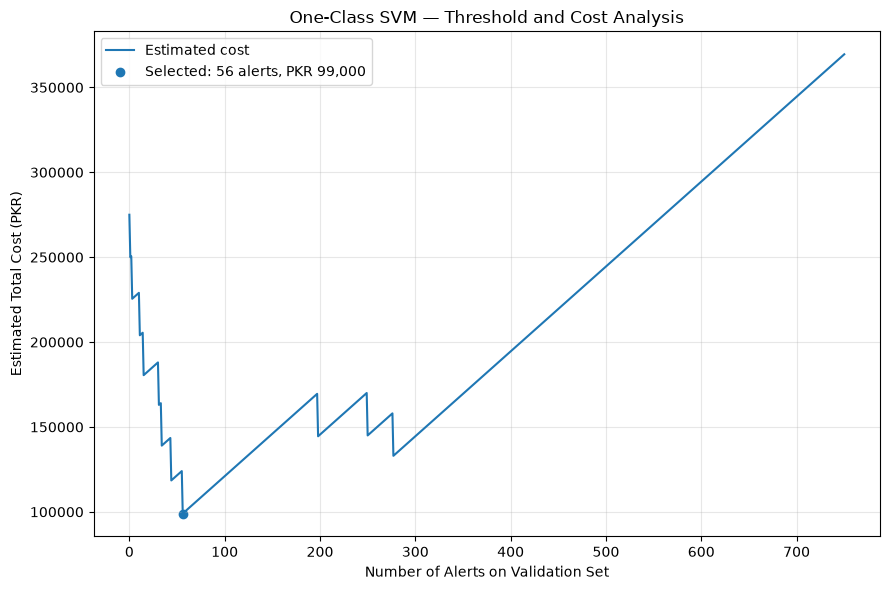

Threshold cost chart saved to:
C:\Users\ahmed\Desktop\4th project\reports\figures\threshold_cost_curve.png


In [14]:
# --------------------------------------------------
# Phase 14.2 — Threshold / Cost Chart
# --------------------------------------------------

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

cost_file = REPORTS_DIR / "threshold_cost_analysis.csv"

if not cost_file.exists():
    raise FileNotFoundError(
        f"Cost table not found: {cost_file.resolve()}"
    )

cost_data = pd.read_csv(cost_file)

required_columns = {
    "Threshold",
    "Alerts",
    "Total Cost (PKR)"
}

if not required_columns.issubset(cost_data.columns):
    raise ValueError(
        f"Cost table must include: {sorted(required_columns)}"
    )

# Find minimum-cost operating point.
# If costs tie, choose fewer alerts.
minimum_cost = cost_data["Total Cost (PKR)"].min()

best_point = (
    cost_data[
        cost_data["Total Cost (PKR)"] == minimum_cost
    ]
    .sort_values("Alerts")
    .iloc[0]
)

# Show the minimum cost for each alert count
plot_data = (
    cost_data
    .groupby("Alerts", as_index=False)["Total Cost (PKR)"]
    .min()
    .sort_values("Alerts")
)

plt.figure(figsize=(9, 6))

plt.plot(
    plot_data["Alerts"],
    plot_data["Total Cost (PKR)"],
    label="Estimated cost"
)

plt.scatter(
    [best_point["Alerts"]],
    [best_point["Total Cost (PKR)"]],
    label=(
        f"Selected: {int(best_point['Alerts'])} alerts, "
        f"PKR {int(best_point['Total Cost (PKR)']):,}"
    )
)

plt.xlabel("Number of Alerts on Validation Set")
plt.ylabel("Estimated Total Cost (PKR)")
plt.title("One-Class SVM — Threshold and Cost Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

chart_path = FIGURES_DIR / "threshold_cost_curve.png"

plt.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Threshold cost chart saved to:")
print(chart_path)

In [15]:
# --------------------------------------------------
# Phase 14.3 — Evidence Index and File Verification
# --------------------------------------------------

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("..").resolve()
REPORTS_DIR = PROJECT_ROOT / "reports"

evidence_index = """# Week 4 Evidence Index

## Main documentation
- `README.md` — project approach, tools, results, limitations, setup
- `reports/week4_summary.md` — standalone written project summary
- `reports/validation_findings.md` — validation findings, issues, fixes
- `CHANGELOG.md` — development history

## Model evaluation
- `reports/model_comparison_validation.csv`
- `reports/final_test_evaluation.csv`
- `reports/threshold_cost_analysis.csv`

## Charts
- `reports/figures/all_models_pr_curve.png`
- `reports/figures/isolation_forest_pr_curve.png`
- `reports/figures/one_class_svm_pr_curve.png`
- `reports/figures/autoencoder_pr_curve.png`
- `reports/figures/autoencoder_training_loss.png`
- `reports/figures/threshold_cost_curve.png`

## Robustness evidence
- `reports/robustness_test_results.csv`
- `src/robustness.py`

## Suggested screenshots for submission
1. Dataset preview and 1.5% suspicious class distribution
2. Dummy baseline with 98.5% accuracy and zero recall
3. Time-based split and temporal leakage checks
4. Autoencoder training-loss graph
5. Three-model comparison table
6. Combined Precision-Recall graph
7. Cost threshold table and cost graph
8. Robustness table showing 20/20 passed
9. Final test evaluation metrics

Capture screenshots from the real notebook or saved output files.
Do not present suggested screenshots as already captured.
"""

index_path = REPORTS_DIR / "evidence_index.md"
index_path.write_text(evidence_index, encoding="utf-8")

files_to_check = [
    PROJECT_ROOT / "README.md",
    PROJECT_ROOT / "CHANGELOG.md",
    REPORTS_DIR / "week4_summary.md",
    REPORTS_DIR / "validation_findings.md",
    REPORTS_DIR / "evidence_index.md",
    REPORTS_DIR / "model_comparison_validation.csv",
    REPORTS_DIR / "threshold_cost_analysis.csv",
    REPORTS_DIR / "final_test_evaluation.csv",
    REPORTS_DIR / "robustness_test_results.csv",
    REPORTS_DIR / "figures" / "all_models_pr_curve.png",
    REPORTS_DIR / "figures" / "isolation_forest_pr_curve.png",
    REPORTS_DIR / "figures" / "one_class_svm_pr_curve.png",
    REPORTS_DIR / "figures" / "autoencoder_pr_curve.png",
    REPORTS_DIR / "figures" / "autoencoder_training_loss.png",
    REPORTS_DIR / "figures" / "threshold_cost_curve.png",
    PROJECT_ROOT / "src" / "robustness.py",
    PROJECT_ROOT / "notebooks" / "week4_fraud_anomaly_detection.ipynb",
]

verification = pd.DataFrame({
    "File": [
        str(path.relative_to(PROJECT_ROOT))
        for path in files_to_check
    ],
    "Exists": [
        path.is_file()
        for path in files_to_check
    ]
})

print("PHASE 14 EVIDENCE CHECK")
print("=======================")
display(verification)

missing = verification.loc[
    ~verification["Exists"], "File"
].tolist()

print("\nMissing files:", len(missing))

if missing:
    print("Review these files:")
    for filename in missing:
        print("-", filename)
else:
    print("All key Phase 14 files exist.")

PHASE 14 EVIDENCE CHECK


,File,Exists
0,README.md,True
1,CHANGELOG.md,True
2,reports\week4_summary.md,True
3,reports\validation_findings.md,True
4,reports\evidence_index.md,True
5,reports\model_comparison_validation.csv,True
6,reports\threshold_cost_analysis.csv,True
7,reports\final_test_evaluation.csv,True
8,reports\robustness_test_results.csv,True
9,reports\figures\all_models_pr_curve.png,True



Missing files: 0
All key Phase 14 files exist.
